#Exploring Phytoplankton Drivers with ML

Setting up the dataset:



In [ ]:
# Downloading necessary packages
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [ ]:
# Loading the excel file into a url
# NOTE: Access to the original dataset is limited
# you can use your own datset with url =""
phyto_dr = pd.read_csv(url, parse_dates=['Date'])

In [ ]:
# Making a constant to store all phytoplankton columns into one list
PHYTO_COLS = [
 'Asterionellopsis',
 'Ceratium',
 'Chaetoceros',
 'DactFragCeratul',
 'Dinophysis',
 'Myrionectarubra',
 'P_minimum',
 'P_texanum',
 'Prorocentrum']

PHYTO_COLS

['Asterionellopsis',
 'Ceratium',
 'Chaetoceros',
 'DactFragCeratul',
 'Dinophysis',
 'Myrionectarubra',
 'P_minimum',
 'P_texanum',
 'Prorocentrum']

Data exploration:

In [ ]:
# Inspecting the first five values in the dataframe
# (colab caps the possible columns to view at 20)
phyto_dr.head()

,Date,Asterionellopsis,Ceratium,Chaetoceros,DactFragCeratul,Dinophysis,Myrionectarubra,P_minimum,P_texanum,Prorocentrum,...,LA3_salinity_25,LA3_salinity_50,tabs_j_salinity_0,tabs_j_salinity_25,tabs_j_salinity_50,Miss_dchg,sp_cond_BaratariaBay_LA,streamlevel_BaratariaBay_LA,gage_height_Caillou_Bay_LA,sp_cond__Caillou_Bay_LA
0,2007-09-08 13:00:00,0.0,0.0,0.0,0.0,0.0,0.583576,0.583576,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2007-09-08 14:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2007-09-08 15:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2007-09-08 16:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2007-09-08 17:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Listing all the columns inside the phyto_dr dataset
print(list(phyto_dr.columns))

['Date', 'Asterionellopsis', 'Ceratium', 'Chaetoceros', 'DactFragCeratul', 'Dinophysis', 'Myrionectarubra', 'P_minimum', 'P_texanum', 'Prorocentrum', 'SPDP42044a', 'CDIR42044a', 'CSPD42044a', 'WDIR42044h', 'WSPD42044h', 'WGST42044h', 'PRES42044h', 'ATMP42044h', 'WTMP42044h', 'DEWP42044h', 'TIDE42044h', 'SPDP42045a', 'CDIR42045a', 'CSPD42045a', 'WDIR42045h', 'WSPD42045h', 'PRES42045h', 'ATMP42045h', 'WTMP42045h', 'DEWP42045h', 'TIDE42045h', 'SPDP42046a', 'CDIR42046a', 'CSPD42046a', 'WDIR42046h', 'WSPD42046h', 'ATMP42046h', 'WTMP42046h', 'DEWP42046h', 'TIDE42046h', 'SPDP42048a', 'CDIR42048a', 'CSPD42048a', 'SPDP42049a', 'CDIR42049a', 'CSPD42049a', 'SPDP42050a', 'CDIR42050a', 'CSPD42050a', 'SPDP42051a', 'CDIR42051a', 'CSPD42051a', 'PWLVBOBHAL', 'ATMPBOBHAL', 'WSPDBOBHAL', 'WDIRBOBHAL', 'PWLVLCCAPA', 'ATMPLCCAPA', 'WSPDLCCAPA', 'WDIRLCCAPA', 'ATMPMANER5', 'WSPDMANER5', 'WDIRMANER5', 'RAINMANER5', 'SALTMANER5', 'PHMANER5', 'DOMANER5', 'SATMANER5', 'TURBMANER5', 'CHLAMANER5', 'DPTHMANER5', '

Extra data cleaning:

In [ ]:
# Seeing which columns have the greatest amount of missing data
missing_percent = (phyto_dr.isna().sum() / len(phyto_dr)) * 100

missing_percent.sort_values(ascending=False).head(20)

,0
tabs_d_salinity_50,100.0
tabs_b_salinity_25,100.0
tabs_b_salinity_50,100.0
tabs_r_salinity_25,100.0
TIDE42045h,100.0
TIDE42044h,100.0
tabs_r_salinity_50,100.0
tabs_f_salinity_25,100.0
tabs_f_salinity_50,100.0
tabs_d_salinity_25,100.0


In [ ]:
# Removing the columns that are missing 90% or more values
keep = int(len(phyto_dr) * 0.50)

phyto_dr = phyto_dr.dropna(axis = 1, thresh = keep)

In [ ]:
# Checking how many observations and columns are in the dataset
# 76,569 observations and 208 variables
phyto_dr.shape


(76569, 54)

In [ ]:
# Looking at all the columns that are left after cleaning
print(list(phyto_dr.columns))

['Date', 'Asterionellopsis', 'Ceratium', 'Chaetoceros', 'DactFragCeratul', 'Dinophysis', 'Myrionectarubra', 'P_minimum', 'P_texanum', 'Prorocentrum', 'WDIR42046h', 'WSPD42046h', 'PWLVBOBHAL', 'ATMPBOBHAL', 'WSPDBOBHAL', 'WDIRBOBHAL', 'SALTMANER5', 'PHMANER5', 'DOMANER5', 'SATMANER5', 'TURBMANER5', 'CHLAMANER5', 'DPTHMANER5', 'PWLVPIER21', 'WDIRptat2h', 'WSPDptat2h', 'TIDEptat2h', 'WD_ETABS_B_m', 'WD_NTABS_B_m', 'ATMPTABS_B_m', 'GUSTTABS_B_m', 'WDIRTABS_B_m', 'VELETABS_B_v', 'VELNTABS_B_v', 'CVELTABS_B_v', 'CDIRTABS_B_v', 'CONDTABS_B_w', 'SALTTABS_B_w', 'DENSTABS_B_w', 'VELETABS_D_v', 'VELNTABS_D_v', 'WD_ETABS_K_m', 'WD_NTABS_K_m', 'WDIRTABS_K_m', 'VELETABS_K_v', 'VELNTABS_K_v', 'CONDTABS_K_w', 'SALTTABS_K_w', 'DENSTABS_K_w', 'Miss_dchg', 'sp_cond_BaratariaBay_LA', 'streamlevel_BaratariaBay_LA', 'gage_height_Caillou_Bay_LA', 'sp_cond__Caillou_Bay_LA']


Adding time series features for all models:

In [ ]:
# Removing NaN values from Dinophysis and creating a new dataframe
phyto_trainset = phyto_dr.dropna(subset=['Dinophysis']).copy()

In [ ]:
# Creating prediction targets for forecasting and storing them in our training dataset
# (shifting the values in the column up by 24, 168, 336 hours)
# (fast-forwarding to the values at 24, 168, 336 hours)

phyto_trainset["target_24h"] = phyto_trainset["Dinophysis"].shift(-24)
phyto_trainset["target_168h"] = phyto_trainset["Dinophysis"].shift(-168)
phyto_trainset["target_336h"] = phyto_trainset["Dinophysis"].shift(-336)
phyto_trainset["target_504h"] = phyto_trainset["Dinophysis"].shift(-504)

In [ ]:
# Putting lag columns into our training dataset
# (shifts the values in the column down by 24, 168, 336)

phyto_trainset["lag_24h"] = phyto_trainset['Dinophysis'].shift(24)
phyto_trainset["lag_168h"] = phyto_trainset['Dinophysis'].shift(168)
phyto_trainset["lag_336h"] = phyto_trainset['Dinophysis'].shift(336)
phyto_trainset["lag_504h"] = phyto_trainset["Dinophysis"].shift(504)


# Remove rows that don't have enough time points for lags to use
lag_cols = ['lag_24h', 'lag_168h', 'lag_336h', 'lag_504h']

phyto_trainset = phyto_trainset.dropna(subset = lag_cols)


In [ ]:
# Removing the NaN rows from the target column
phyto_trainset = phyto_trainset.dropna(subset = ['target_24h'])
phyto_trainset = phyto_trainset.dropna(subset = ['target_168h'])
phyto_trainset = phyto_trainset.dropna(subset = ['target_336h'])
phyto_trainset = phyto_trainset.dropna(subset = ['target_504h'])

Looking at the phytoplankton variables:

In [ ]:
phyto_trainset = phyto_trainset.fillna(phyto_dr.mean(numeric_only=True))

In [ ]:
# Checking how many missing values are in the phytoplankton data
phyto_trainset.isna().sum()

,0
Date,0
Asterionellopsis,0
Ceratium,0
Chaetoceros,0
DactFragCeratul,0
...,...
target_504h,0
lag_24h,0
lag_168h,0
lag_336h,0


In [ ]:
# Descriptive statistics for each phytoplankton species
phyto_dr[PHYTO_COLS].describe()

,Asterionellopsis,Ceratium,Chaetoceros,DactFragCeratul,Dinophysis,Myrionectarubra,P_minimum,P_texanum,Prorocentrum
count,60795.000000,60795.000000,60795.000000,60795.000000,60795.000000,60795.000000,60795.000000,60795.000000,60795.000000
mean,3.500856,0.168426,4.612721,5.826887,0.702330,0.807533,1.863238,1.629809,0.443680
std,9.922872,0.533083,12.878002,23.872856,3.432079,4.251717,10.199184,9.521705,1.026919
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.265878,0.000000,0.471358,0.415254,0.000000,0.000000,0.337573,0.106767,0.067299
50%,0.976411,0.071789,1.594706,1.450980,0.140386,0.209336,0.727481,0.287499,0.170267
75%,2.998902,0.207336,4.752865,4.364788,0.337246,0.666570,1.398750,0.752112,0.433343
max,393.599842,39.926986,533.482864,793.431425,140.475921,311.828125,548.278521,510.527029,23.209603


## Making the 3 Random Forest Models:
### (1-day, 1-week, and 2-week forecasts)

In [ ]:
# Importing ML packages for modeling and analyzing models
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import randint


# Import packages for tree visualization
from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz

## Code for our 1-day RF Model:

Organizing and splitting the data for 1-day forecast:




---



In [ ]:
# Passing every column except the phytoplankton species, date column(s), and future predictions into X
cols_to_drop = (PHYTO_COLS + ['Date'] + ['target_24h'] + ['target_168h'] + ['target_336h'] + ['target_504h'] + ['lag_504h'])
X = phyto_trainset.drop(columns = cols_to_drop)

# Passing only the target Dinophysis column to y
y = phyto_trainset['target_24h']

# Checking that lag columns made it into training dataset
print("Are all lag columns present in dataset?")
if all(col in X.columns for col in ['lag_24h', 'lag_168h', 'lag_336h']):
  print("yes\n")

# Splitting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, shuffle=False)

# Getting # of rows and columns for data before split
print("Before split:")
print(f"X: {X.shape}")
print(f"y: {y.shape}")

# Verifying that the split data maintains train/test ratio
print("\nAfter split:")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"\ny_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

Are all lag columns present in dataset?
yes

Before split:
X: (59787, 47)
y: (59787,)

After split:
X_train: (47829, 47)
X_test: (11958, 47)

y_train: (47829,)
y_test: (11958,)


Testing 1-day forecast:


In [ ]:
# Making an instance of the Random Forest model with 1000 trees and 6 layers
rf_24h = RandomForestRegressor(
  n_estimators = 1000,
  max_depth = 6,
  random_state = 1234,
  n_jobs = 2)


In [ ]:
# Passing in our training and testing data
from time import time

start = time()
rf_24h.fit(X_train, y_train)
print(f"Finished in {time() - start:.1f} seconds")

Finished in 641.4 seconds


Seeing predictions made for 1-day forecast and evaluating for accuracy:


In [ ]:
# Getting predictions
y_pred_24h = rf_24h.predict(X_test)


# Getting mean absolute error
mae_24h = mean_absolute_error(y_test, y_pred_24h)


# Getting root mean square error
rmse_24h = np.sqrt(mean_squared_error(y_test, y_pred_24h))

# Getting r^2
r2_24h = r2_score(y_test, y_pred_24h)


# Printing results
print(f"MAE: {mae_24h}")
print(f"RMSE: {rmse_24h}")
print(f"R2: {r2_24h}")

MAE: 0.2593938802789849
RMSE: 0.8756613638387765
R2: -5.884775969997289


In [ ]:
# Comparing training predictions to testing predictions
train_pred = rf_24h.predict(X_train)
test_pred = rf_24h.predict(X_test)

print("\n\nTrain R²:", r2_score(y_train, train_pred))
print("Test R²:", r2_score(y_test, test_pred))

print("\n\nTraining")
print(y_train.describe())

print("\nTesting")
print(y_test.describe())
print("\n")



Train R²: 0.859405790550757
Test R²: -5.884775969997289


Training
count    47829.000000
mean         0.851325
std          3.852257
min          0.000000
25%          0.069788
50%          0.151387
75%          0.392436
max        140.475921
Name: target_24h, dtype: float64

Testing
count    11958.000000
mean         0.152251
std          0.333741
min          0.000000
25%          0.000000
50%          0.071731
75%          0.169856
max          6.356669
Name: target_24h, dtype: float64




Plotting 1-day forecast:

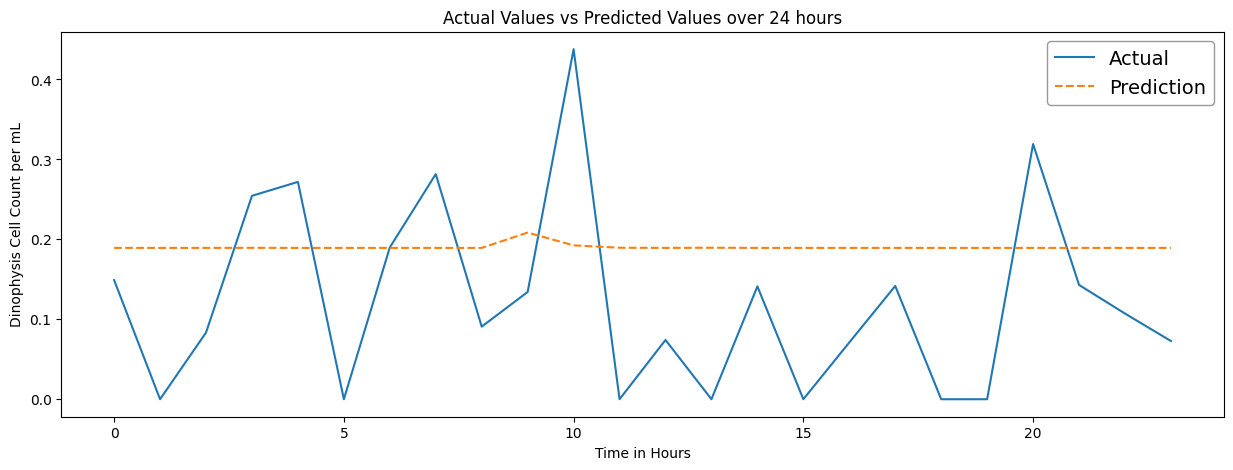

In [ ]:
# Getting predicted values versus actual values for first 24 hours

time_axis = np.arange(0, 12015, 1) # Making an index for the time we have in the testing data


plt.figure(figsize=(15,5))
plt.plot(y_test.values[0:24],
         label="Actual")

plt.plot(y_pred_24h[0:24],
         label="Prediction",
         linestyle="--")

plt.title("Actual Values vs Predicted Values over 24 hours")
plt.xlabel("Time in Hours")
plt.ylabel("Dinophysis Cell Count per mL")

plt.legend(fontsize=14, edgecolor='gray')
plt.show()

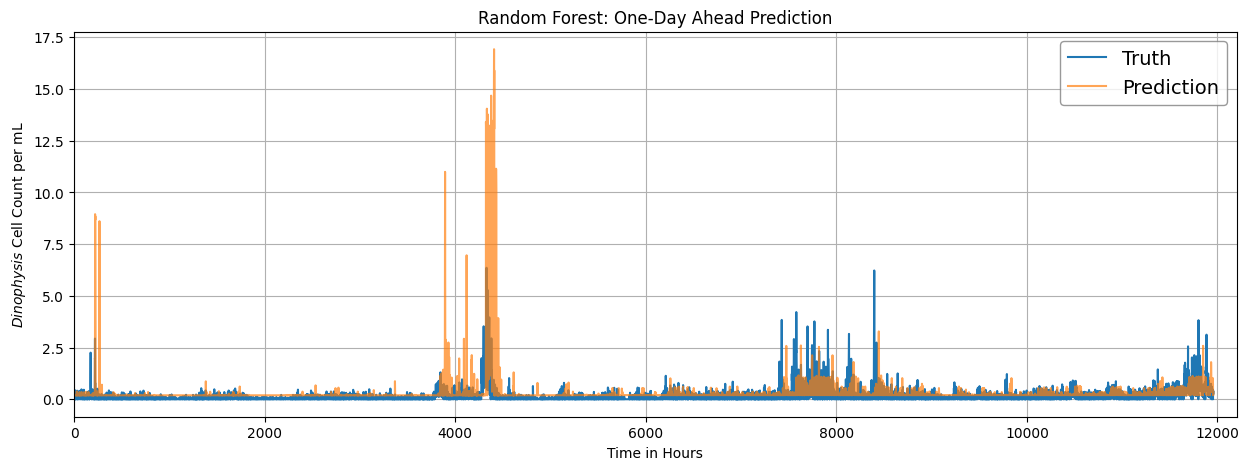

In [ ]:
# Plotting the results for the entire 20% test split

time_axis = np.arange(0, 11958, 1) # Making an index for the time we have in the testing data

plt.figure(figsize=(15,5))
plt.plot(time_axis,
         y_test.values,
         label="Truth")

plt.plot(time_axis,
         y_pred_24h,
         alpha=0.7,
         label="Prediction")

plt.title("Random Forest: One-Day Ahead Prediction")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.xlim(0,12200)
plt.grid(True)

plt.legend(fontsize=14, edgecolor='gray')
plt.show()

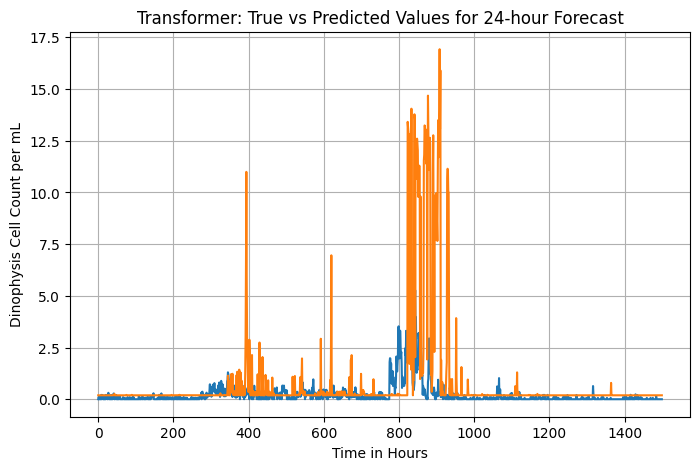

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(y_test.values[3500:5000], label="Truth")
plt.plot(y_pred_24h[3500:5000], label="Predicted")

plt.title("Random Forest: True vs Predicted Values for 24-hour Forecast")
plt.xlabel("Time in Hours")
plt.ylabel("Dinophysis Cell Count per mL")
plt.grid(True)

plt.show()

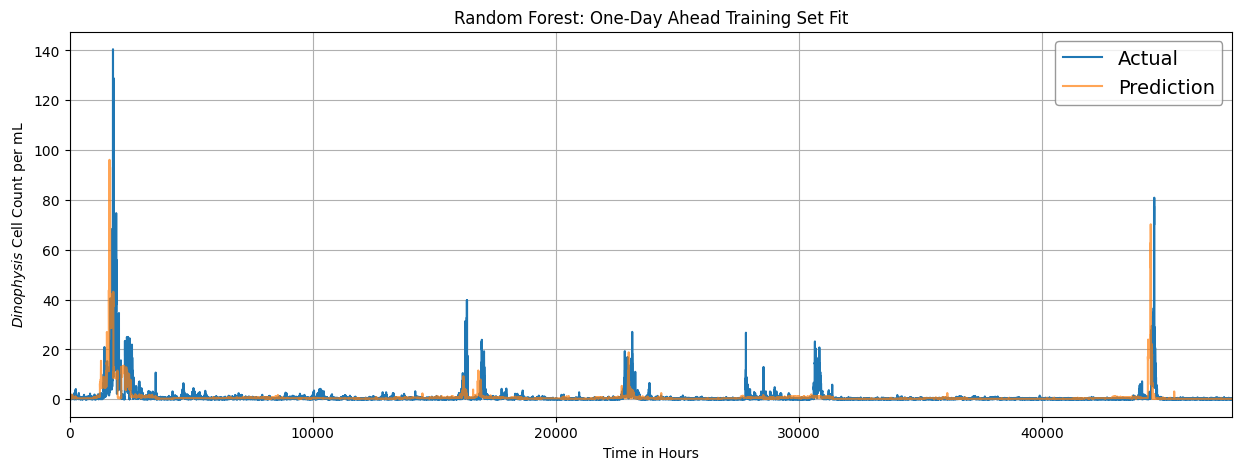

In [ ]:
# Plotting the training results

time_axis = np.arange(0, len(y_train), 1)

plt.figure(figsize=(15,5))
plt.plot(time_axis, y_train.values,
         label="Actual")

plt.plot(time_axis, train_pred,
         alpha=0.7,
         label="Prediction")

plt.title("Random Forest: One-Day Ahead Training Set Fit")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.xlim(0, len(y_train))
plt.grid(True)

plt.legend(fontsize=14, edgecolor='gray')
plt.show()

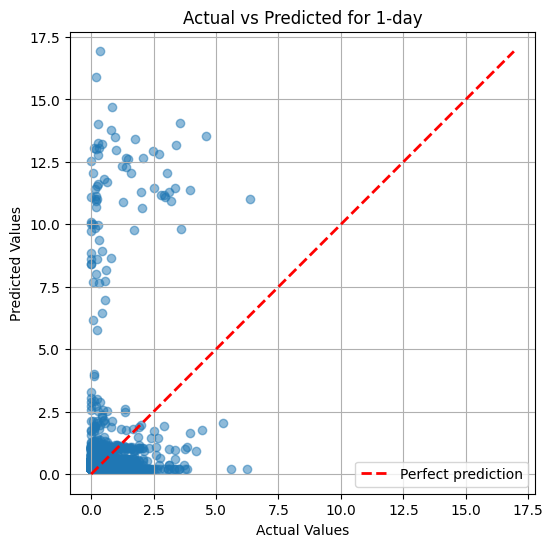

In [ ]:
# Scatterplot of actual vs predicted values
plt.figure(figsize=(6,6))

plt.scatter(y_test.values, y_pred_24h, alpha=0.5)

# Perfect prediction line
lims = [
    min(y_test.min(), y_pred_24h.min()),
    max(y_test.max(), y_pred_24h.max())
]

plt.plot(
    lims,
    lims,
    'r--',
    linewidth=2,
    label='Perfect prediction'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted for 1-day")

plt.xlim(lims)
plt.ylim(lims)

plt.axis("equal")

plt.legend()
plt.grid(True)

plt.show()

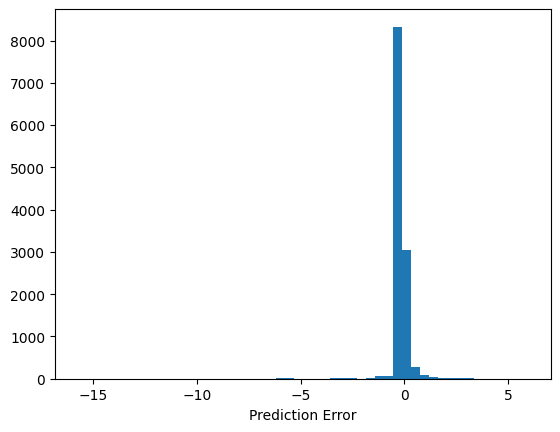

In [ ]:
# Plotting residuals for 1-day forecast
errors = (y_test - y_pred_24h)

plt.hist(errors, bins=50)
plt.xlabel("Prediction Error")
plt.show()

Tree visualization:

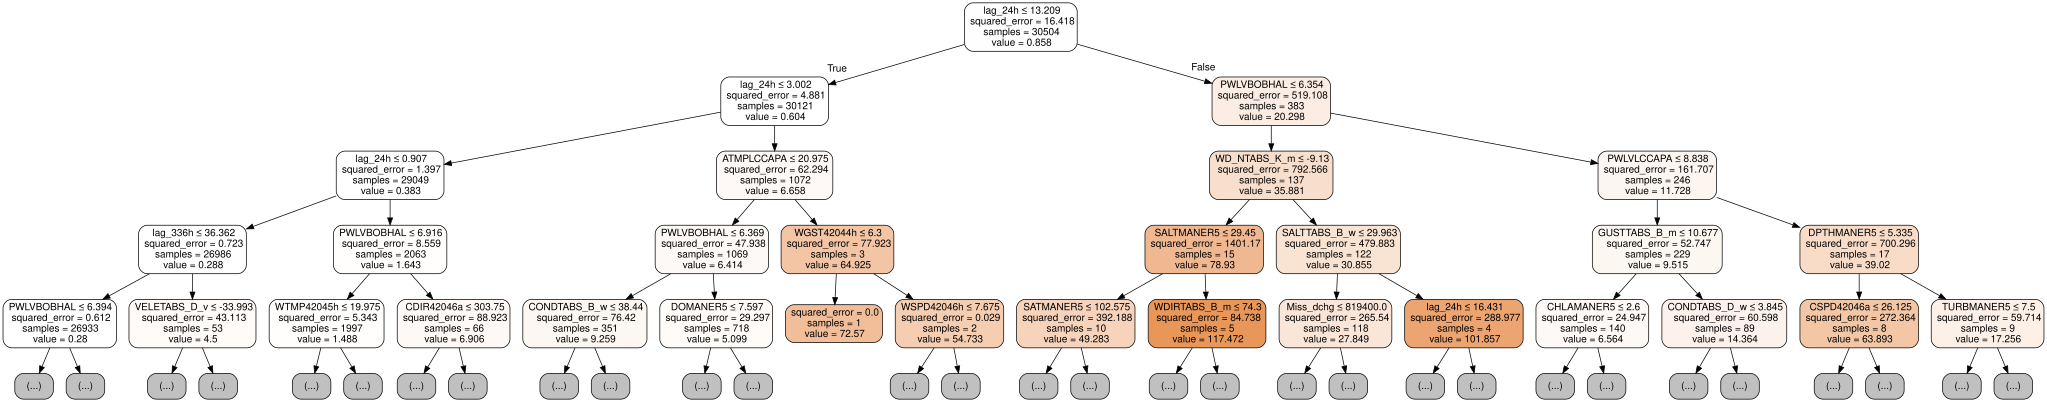

In [ ]:
# Visualizing one of the trees for 1-day forecast

estimator = rf_24h.estimators_[0]

dot_data = export_graphviz(
    estimator,
    out_file=  None,
    feature_names = X.columns,
    filled = True,
    rounded = True,
    special_characters = True,
    max_depth = 4
)

graph = graphviz.Source(dot_data)
graph

Trying time series split for 1-day forecast:

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

# Create 5 train/test splits
tscv = TimeSeriesSplit(n_splits=5)

# Lists to store results from each split
mae_scores = []
rmse_scores = []
r2_scores = []

# Loop through each train/test split
for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):

    # Select the rows for this fold
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Create the Random Forest model
    rf_24h = RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=1234,
        n_jobs=2
    )

    # Train the model
    rf_24h.fit(X_train, y_train)

    # Make predictions
    y_pred = rf_24h.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Save the results
    mae_scores.append(mae)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # Print results for this fold
    print(f"\nFold {fold}")
    print(f"MAE : {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²  : {r2:.3f}")

# Print the average performance across all folds
print("\nAverage Results")
print(f"MAE : {np.mean(mae_scores):.3f}")
print(f"RMSE: {np.mean(rmse_scores):.3f}")
print(f"R²  : {np.mean(r2_scores):.3f}")




Fold 1
MAE : 0.601
RMSE: 1.700
R²  : -0.007

Fold 2
MAE : 0.619
RMSE: 1.558
R²  : -0.102

Fold 3
MAE : 0.405
RMSE: 1.115
R²  : 0.412

Fold 4
MAE : 0.598
RMSE: 3.371
R²  : 0.184

Fold 5
MAE : 0.260
RMSE: 0.631
R²  : -2.134

Average Results
MAE : 0.497
RMSE: 1.675
R²  : -0.329


## Code for our 1-week RF Model:

Organizing and splitting the data for 1-week forecast:


In [ ]:
# Passing every column except the phytoplankton species, date column(s), and future predictions into X
cols_to_drop = (PHYTO_COLS + ['Date'] + ['target_24h'] + ['target_168h'] + ['target_336h'] + ['target_504h'] + ['lag_24h'])
X = phyto_trainset.drop(columns = cols_to_drop)

# Passing only the target Dinophysis column to y
y = phyto_trainset['target_168h']

# Checking that lag columns made it into training dataset
print("Are all lag columns present in dataset?")
if all(col in X.columns for col in ['lag_168h', 'lag_336h', 'lag_504h']):
  print("yes\n")

# Splitting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, shuffle=False)

# Getting # of rows and columns for data before split
print("Before split:")
print(f"X: {X.shape}")
print(f"y: {y.shape}")

# Verifying that the split data maintains train/test ratio
print("\nAfter split:")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"\ny_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

Are all lag columns present in dataset?
yes

Before split:
X: (59787, 47)
y: (59787,)

After split:
X_train: (47829, 47)
X_test: (11958, 47)

y_train: (47829,)
y_test: (11958,)


Testing 1-week forecast:

In [ ]:
# Making an instance of the Random Forest model with 1000 trees and 6 layers
rf_168h = RandomForestRegressor(
    n_estimators = 1000,
    max_depth = 6,
    random_state = 1234,
    n_jobs = 2)

In [ ]:
# Passing in our training and testing data
from time import time

rf_168h.fit(X_train, y_train)
print(f"Finished in {time() - start:.1f} seconds")

Finished in 3058.0 seconds


Seeing predictions made for 1-week forecast and evalutating for accuracy:

In [ ]:
# Getting predictions
y_pred_168h = rf_168h.predict(X_test)


# Getting mean absolute error
mae_168h = mean_absolute_error(y_test, y_pred_168h)


# Getting root mean square error
rmse_168h = np.sqrt(mean_squared_error(y_test, y_pred_168h))

# Getting r^2
r2_168h = r2_score(y_test, y_pred_168h)


# Printing results
print(f"MAE: {mae_168h}")
print(f"RMSE: {rmse_168h}")
print(f"R2: {r2_168h}")

MAE: 0.8777821032678624
RMSE: 1.8862933943475528
R2: -30.844258537876872


In [ ]:
# Comparing training predictions to testing predictions
train_pred = rf_168h.predict(X_train)
test_pred = rf_168h.predict(X_test)

print("\n\nTrain R²:", r2_score(y_train, train_pred))
print("Test R²:", r2_score(y_test, test_pred))

print("\n\nTraining")
print(y_train.describe())

print("\nTesting")
print(y_test.describe())
print("\n")



Train R²: 0.8177553228051482
Test R²: -30.844258537876872


Training
count    47829.000000
mean         0.850206
std          3.852339
min          0.000000
25%          0.069771
50%          0.150804
75%          0.388572
max        140.475921
Name: target_168h, dtype: float64

Testing
count    11958.000000
mean         0.153226
std          0.334281
min          0.000000
25%          0.000000
50%          0.071807
75%          0.171966
max          6.356669
Name: target_168h, dtype: float64




Plotting 1-week forecast:

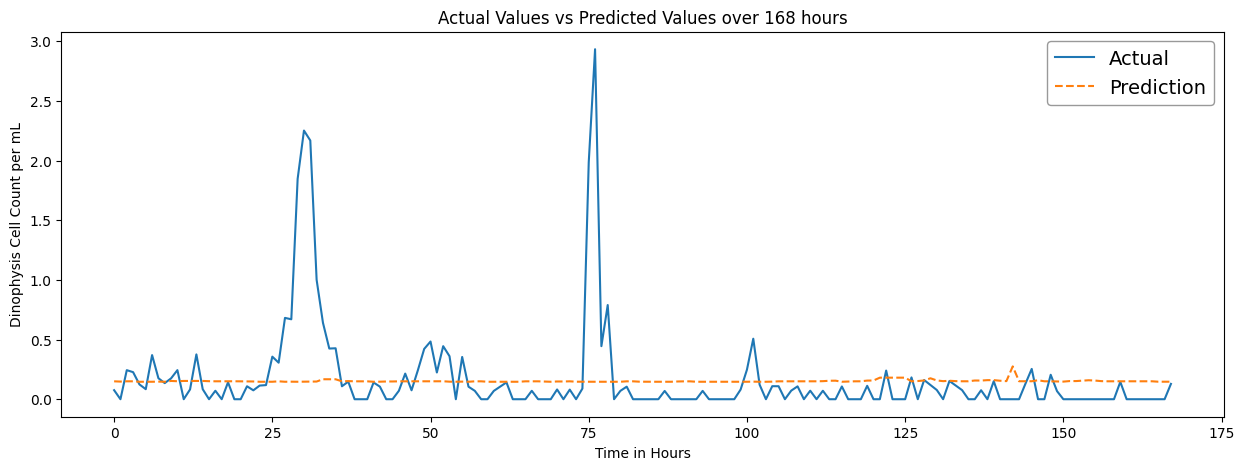

In [ ]:
# Getting predicted values versus actual values for 168 hours

time_axis = np.arange(0, 12015, 1) # Making an index for the time we have in the testing data


plt.figure(figsize=(15,5))
plt.plot(y_test.values[0:168],
         label="Actual")

plt.plot(y_pred_168h[0:168],
         label="Prediction",
         linestyle="--")

plt.title("Actual Values vs Predicted Values over 168 hours")
plt.xlabel("Time in Hours")
plt.ylabel("Dinophysis Cell Count per mL")

plt.legend(fontsize=14, edgecolor='gray')
plt.show()

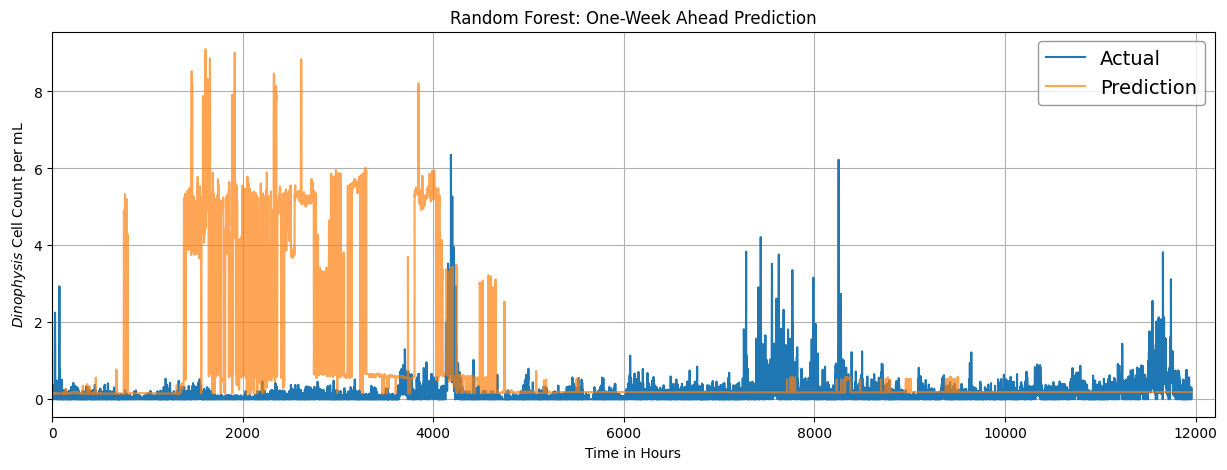

In [ ]:
# Plotting the results for the entire 20% test split

time_axis = np.arange(0, 11958, 1) # Making an index for the time we have in the testing data

plt.figure(figsize=(15,5))
plt.plot(time_axis, y_test.values,
         label="Actual")

plt.plot(time_axis, y_pred_168h,
         alpha=0.7,
         label="Prediction")

plt.title("Random Forest: One-Week Ahead Prediction")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.xlim(0,12200)
plt.grid(True)

plt.legend(fontsize=14, edgecolor='gray')
plt.show()

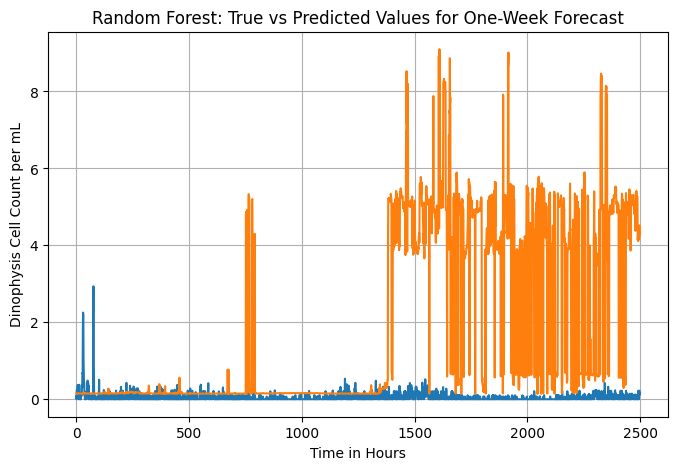

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(y_test.values[0:2500], label="Truth")
plt.plot(y_pred_168h[0:2500], label="Predicted")

plt.title("Random Forest: True vs Predicted Values for One-Week Forecast")
plt.xlabel("Time in Hours")
plt.ylabel("Dinophysis Cell Count per mL")
plt.grid(True)

plt.show()

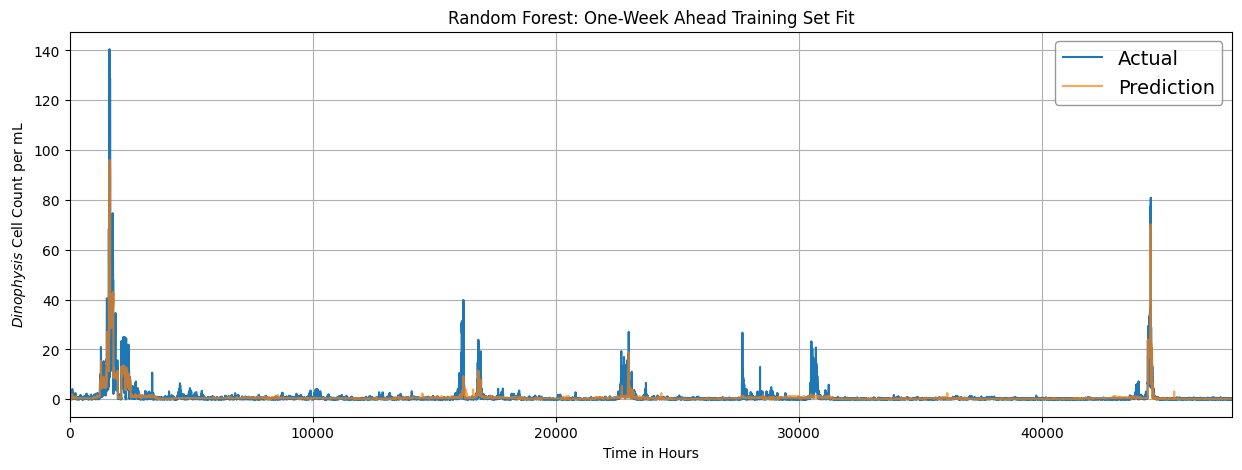

In [ ]:
# Plotting the training results

time_axis = np.arange(0, len(y_train), 1)

plt.figure(figsize=(15,5))
plt.plot(time_axis, y_train.values,
         label="Actual")

plt.plot(time_axis, train_pred,
         alpha=0.7,
         label="Prediction")

plt.title("Random Forest: One-Week Ahead Training Set Fit")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.xlim(0, len(y_train))
plt.grid(True)

plt.legend(fontsize=14, edgecolor='gray')
plt.show()

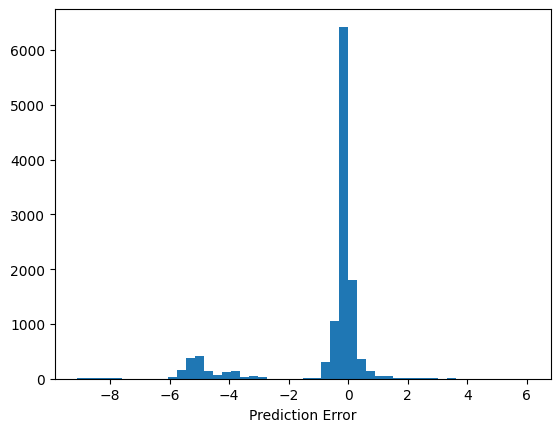

In [ ]:
# Plotting residuals for 1-week forecast
errors = (y_test - y_pred_168h)

plt.hist(errors, bins=50)
plt.xlabel("Prediction Error")
plt.show()

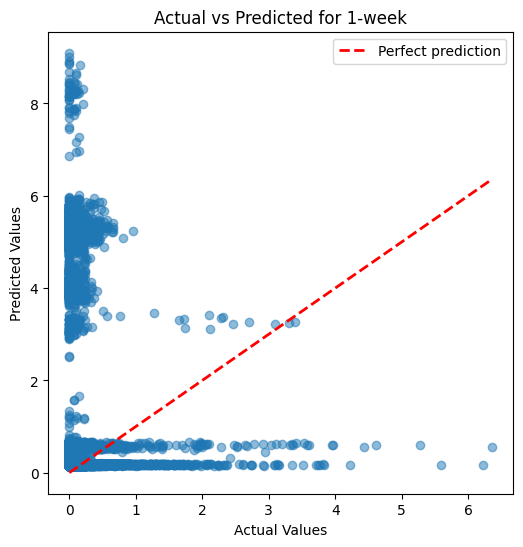

In [ ]:
# Scatterplot of actual vs predicted values
plt.figure(figsize=(6,6))
plt.scatter(y_test.values, y_pred_168h, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2,
    label='Perfect prediction'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted for 1-week")
plt.legend()
plt.show()

In [ ]:

y_train_pred = y_train_pred.flatten()

# Convert back from log scale
train_pred = np.expm1(y_train_pred)
y_train_true = np.expm1(y_train)

NameError: name 'y_train_pred' is not defined

Tree visualization:

In [ ]:
# Visualizing one of the trees for 1-week forecast

estimator = rf_168h.estimators_[0]

dot_data = export_graphviz(
    estimator,
    out_file=  None,
    feature_names = X.columns,
    filled = True,
    rounded = True,
    special_characters = True,
    max_depth = 4
)

graph = graphviz.Source(dot_data)
graph

Trying time series split for 1-week forecast:

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

# Create 5 train/test splits
tscv = TimeSeriesSplit(n_splits=5)

# Lists to store results from each split
mae_scores = []
rmse_scores = []
r2_scores = []

# Loop through each train/test split
for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):

    # Select the rows for this fold
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Create the Random Forest model
    rf_168h = RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=1234,
        n_jobs=2
    )

    # Train the model
    rf_168h.fit(X_train, y_train)

    # Make predictions
    y_pred = rf_168h.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Save the results
    mae_scores.append(mae)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # Print results for this fold
    print(f"\nFold {fold}")
    print(f"MAE : {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²  : {r2:.3f}")

# Print the average performance across all folds
print("\nAverage Results")
print(f"MAE : {np.mean(mae_scores):.3f}")
print(f"RMSE: {np.mean(rmse_scores):.3f}")
print(f"R²  : {np.mean(r2_scores):.3f}")




Fold 1
MAE : 0.593
RMSE: 1.732
R²  : -0.043

Fold 2
MAE : 0.735
RMSE: 1.566
R²  : -0.111

Fold 3
MAE : 0.567
RMSE: 1.643
R²  : -0.273

Fold 4
MAE : 0.935
RMSE: 3.729
R²  : 0.003

Fold 5
MAE : 0.198
RMSE: 0.365
R²  : -0.044

Average Results
MAE : 0.606
RMSE: 1.807
R²  : -0.094


## Code for our 2-Week RF Model:

Organizing and splitting the data for 2-week forecast:

In [ ]:
# Passing every column except the phytoplankton species, date column(s), and future predictions into X
cols_to_drop = (PHYTO_COLS + ['Date'] + ['target_24h'] + ['target_168h'] + ['target_336h'] + ['target_504h'] + ['lag_24h'])
X = phyto_trainset.drop(columns = cols_to_drop)

# Passing only the target Dinophysis column to y
y = phyto_trainset['target_336h']

# Checking that lag columns made it into training dataset
print("Are all lag columns present in dataset?")
if all(col in X.columns for col in ['lag_168h', 'lag_336h', 'lag_504h']):
  print("yes\n")

# Splitting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, shuffle=False)

# Getting # of rows and columns for data before split
print("Before split:")
print(f"X: {X.shape}")
print(f"y: {y.shape}")

# Verifying that the split data maintains train/test ratio
print("\nAfter split:")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"\ny_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

Are all lag columns present in dataset?
yes

Before split:
X: (59787, 47)
y: (59787,)

After split:
X_train: (47829, 47)
X_test: (11958, 47)

y_train: (47829,)
y_test: (11958,)


Testing 2-week forecast:

In [ ]:
# Making an instance of the Random Forest model with 1000 trees and 6 layers
rf_336h = RandomForestRegressor(
    n_estimators = 1000,
    max_depth = 6,
    random_state = 1234,
    n_jobs = 2)

In [ ]:
# Passing in our training and testing data
from time import time

start = time()
rf_336h.fit(X_train, y_train)
print(f"Finished in {time() - start:.1f} seconds")

Finished in 669.6 seconds


Seeing predictions made for 2-week forecast and evaluating for accuracy:

In [ ]:
# Getting predictions
y_pred_336h = rf_336h.predict(X_test)

# Getting mean absolute error
mae_336h = mean_absolute_error(y_test, y_pred_336h)

# Getting root mean square error
rmse_336h = np.sqrt(mean_squared_error(y_test, y_pred_336h))

# Getting r^2
r2_336h = r2_score(y_test, y_pred_336h)

# Printing results
print(f"MAE: {mae_336h}")
print(f"RMSE: {rmse_336h}")
print(f"R2: {r2_336h}")

MAE: 1.1785999009647476
RMSE: 2.4650873792980605
R2: -54.305286672102255


In [ ]:
# Comparing training predictions to testing predictions
train_pred = rf_336h.predict(X_train)
test_pred = rf_336h.predict(X_test)

print("\n\nTrain R²:", r2_score(y_train, train_pred))
print("Test R²:", r2_score(y_test, test_pred))

print("\n\nTraining")
print(y_train.describe())

print("\nTesting")
print(y_test.describe())
print("\n")



Train R²: 0.8629265579435639
Test R²: -54.305286672102255


Training
count    47829.000000
mean         0.848492
std          3.852397
min          0.000000
25%          0.069703
50%          0.149789
75%          0.384263
max        140.475921
Name: target_336h, dtype: float64

Testing
count    11958.000000
mean         0.153242
std          0.331487
min          0.000000
25%          0.000000
50%          0.072246
75%          0.175221
max          6.356669
Name: target_336h, dtype: float64




Plotting 2-week forecast:

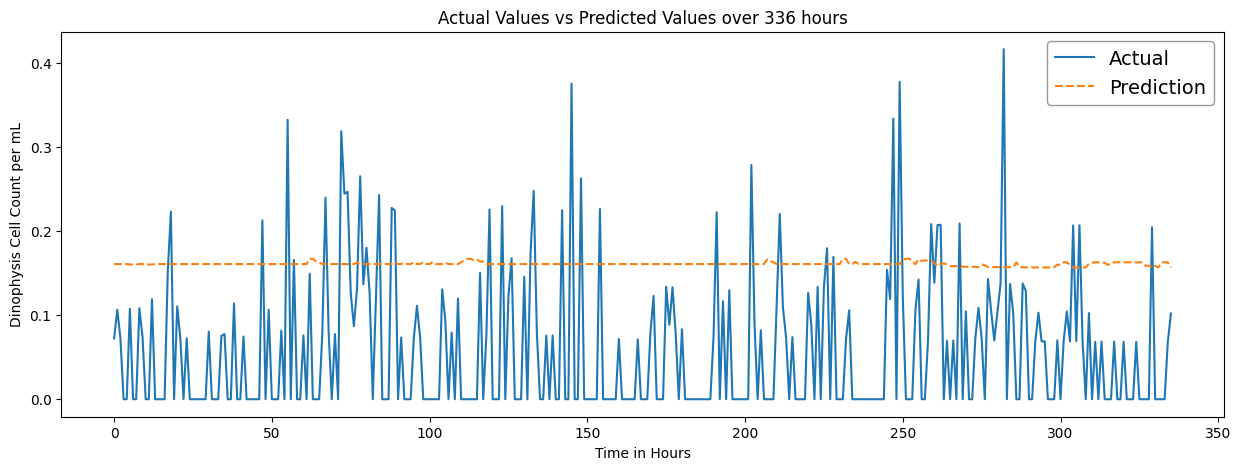

In [ ]:
# Getting predicted values versus actual values for 336 hours

time_axis = np.arange(0, 12015, 1) # Making an index for the time we have in the testing data


plt.figure(figsize=(15,5))
plt.plot(y_test.values[0:336],
         label="Actual")

plt.plot(y_pred_336h[0:336],
         label="Prediction",
         linestyle="--")

plt.title("Actual Values vs Predicted Values over 336 hours")
plt.xlabel("Time in Hours")
plt.ylabel("Dinophysis Cell Count per mL")

plt.legend(fontsize=14, edgecolor='gray')
plt.show()

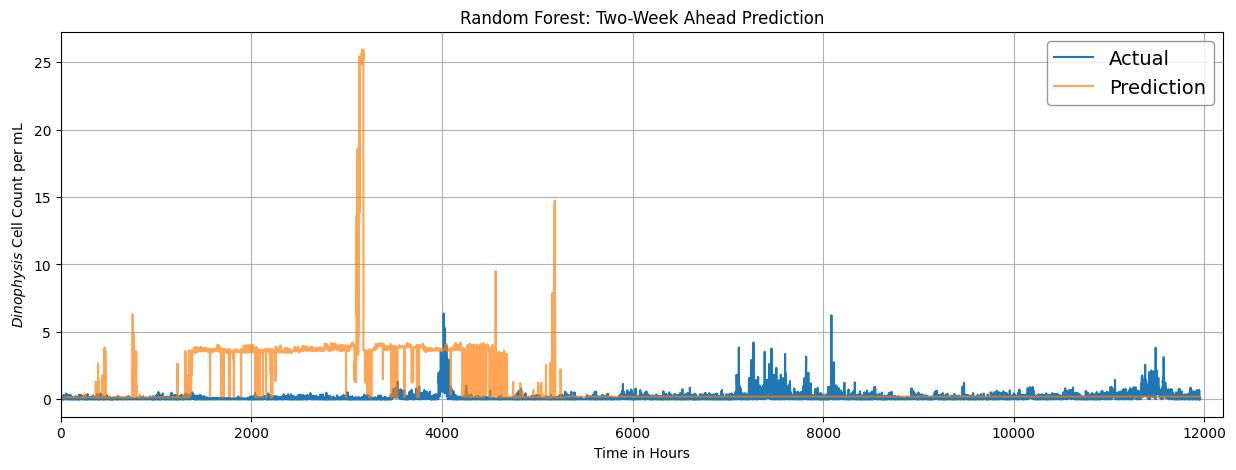

In [ ]:
# Plotting the results for the entire 20% test split

time_axis = np.arange(0, 11958, 1) # Making an index for the time we have in the testing data

plt.figure(figsize=(15,5))
plt.plot(time_axis, y_test.values,
         label="Actual")

plt.plot(time_axis, y_pred_336h,
         alpha=0.7,
         label="Prediction")

plt.title("Random Forest: Two-Week Ahead Prediction")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.xlim(0,12200)
plt.grid(True)

plt.legend(fontsize=14, edgecolor='gray')
plt.show()

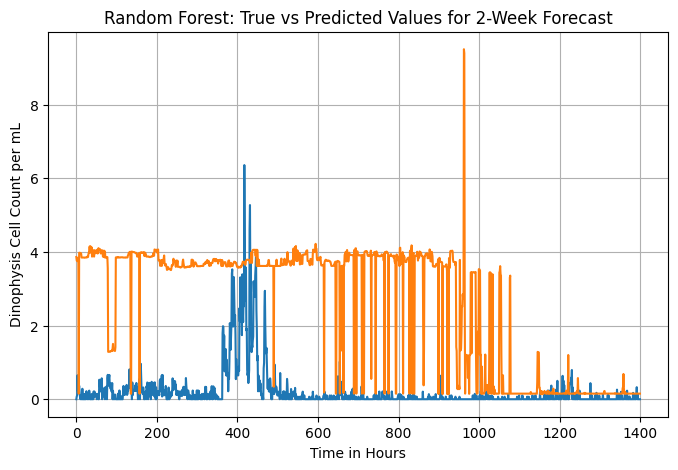

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(y_test.values[3600:5000], label="Truth")
plt.plot(y_pred_336h[3600:5000], label="Predicted")

plt.title("Random Forest: True vs Predicted Values for 2-Week Forecast")
plt.xlabel("Time in Hours")
plt.ylabel("Dinophysis Cell Count per mL")
plt.grid(True)

plt.show()

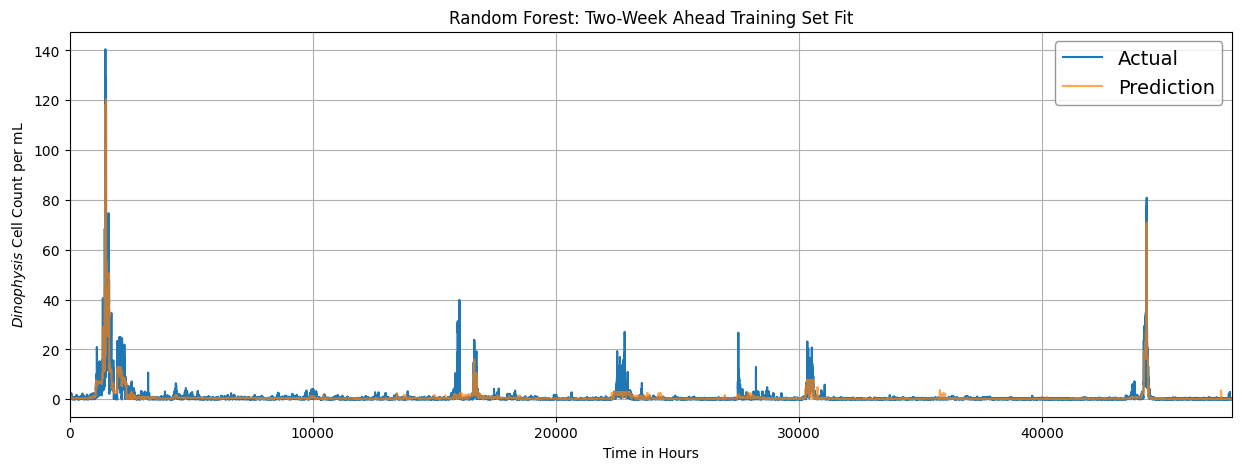

In [ ]:
# Plotting the training results

time_axis = np.arange(0, len(y_train), 1)

plt.figure(figsize=(15,5))
plt.plot(time_axis, y_train.values,
         label="Actual")

plt.plot(time_axis, train_pred,
         alpha=0.7,
         label="Prediction")

plt.title("Random Forest: Two-Week Ahead Training Set Fit")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.xlim(0, len(y_train))
plt.grid(True)

plt.legend(fontsize=14, edgecolor='gray')
plt.show()

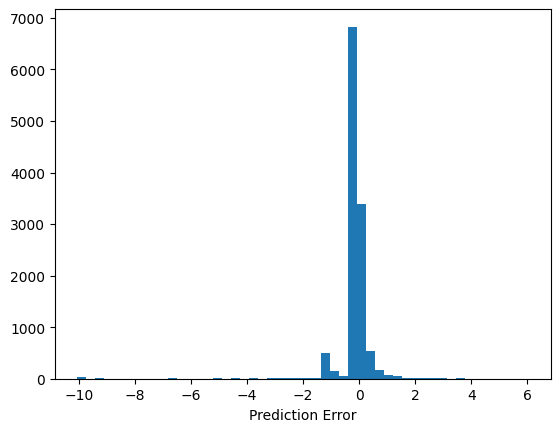

In [ ]:
# Plotting residuals for 2-week forecast
errors = (y_test - y_pred_336h)

plt.hist(errors, bins=50)
plt.xlabel("Prediction Error")
plt.show()

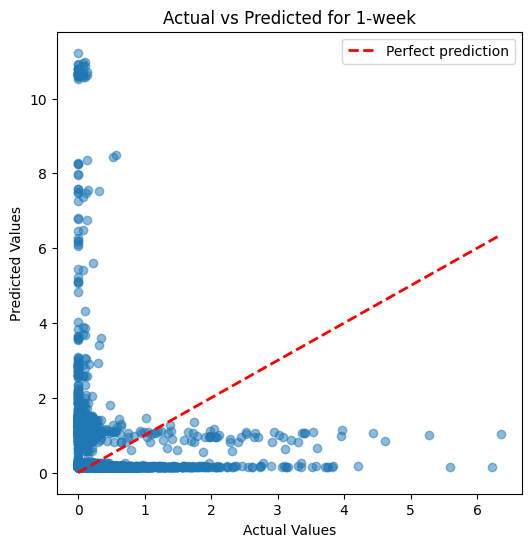

In [ ]:
# plt.scatter(y_test.values, y_pred_24h)
plt.figure(figsize=(6,6))
plt.scatter(y_test.values, y_pred_336h, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2,
    label='Perfect prediction'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted for 1-week")
plt.legend()
plt.show()

Tree visualization:

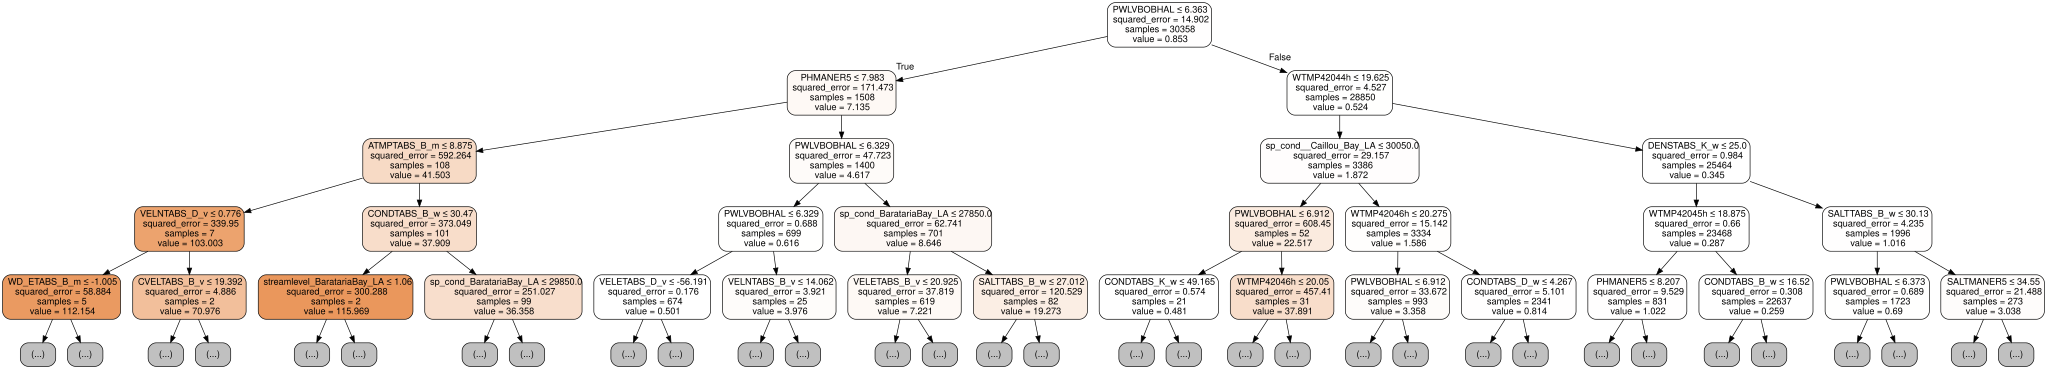

In [ ]:
# Visualizing one of the trees for 1-week forecast
estimator = rf_336h.estimators_[0]

dot_data = export_graphviz(
    estimator,
    out_file=  None,
    feature_names = X.columns,
    filled = True,
    rounded = True,
    special_characters = True,
    max_depth = 4
)

graph = graphviz.Source(dot_data)
graph

Trying time series split for 2-week forecast:

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

# Create 5 train/test splits
tscv = TimeSeriesSplit(n_splits=5)

# Lists to store results from each split
mae_scores = []
rmse_scores = []
r2_scores = []

# Loop through each train/test split
for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):

    # Select the rows for this fold
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Create the Random Forest model
    rf_168h = RandomForestRegressor(
        n_estimators=100,
        max_depth=5,
        random_state=1234,
        n_jobs=2
    )

    # Train the model
    rf_336h.fit(X_train, y_train)

    # Make predictions
    y_pred = rf_168h.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Save the results
    mae_scores.append(mae)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    # Print results for this fold
    print(f"\nFold {fold}")
    print(f"MAE : {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²  : {r2:.3f}")

# Print the average performance across all folds
print("\nAverage Results")
print(f"MAE : {np.mean(mae_scores):.3f}")
print(f"RMSE: {np.mean(rmse_scores):.3f}")
print(f"R²  : {np.mean(r2_scores):.3f}")



## Working with the Amazon Chronos-2 Transformer:


### 24-hour Forecast:

Part 1 (Getting the data ready for 24-hour forecast):



In [ ]:
# Re-downloading the packages we used above (to avoid scrolling back and forth)
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

In [ ]:
# Loading our data into a url and creating a new dataframe specifically for the transformer
# NOTE: Access to the original dataset is limited
# you can use your own datset with url =""
chronos_df = pd.read_csv(url, parse_dates=['Date'])

Data cleaning:

In [ ]:
# Keeping only the date and dinophysis columns
chronos_train = chronos_df[["Date", "Dinophysis"]].copy()

In [ ]:
# Looking at all the variables
show_df = list(chronos_train.columns)
print(show_df)

['Date', 'Dinophysis']


Part 2 (Setting up our data for 24-hour forecast)



In [ ]:
# Renaming variables in the format that Chronos expects
chronos_train = chronos_train.rename(
    columns={
        "Date": "timestamp",
        "Dinophysis": "target"
    }
)

chronos_train = chronos_train.sort_values("timestamp")
chronos_train["item_id"] = "station1"

In [ ]:
# Tells the model how many steps ahead to forecast
prediction_length = 24

In [ ]:
# Doing train/test split
context_df = chronos_train.iloc[:-prediction_length].copy()
future_df = chronos_train.iloc[-prediction_length:].copy()

# Dropping the target column to avoid data leakage
future_df = future_df.drop(columns=["target"])

In [ ]:
# Setting the seed so that we get the same output on each run
import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
# Downloading the software for the transformer
%pip install 'chronos-forecasting[extras]>=2.2'

# Getting chronos packages
from chronos import BaseChronosPipeline, Chronos2Pipeline

'''
Make sure you change the runtime settings to be on a GPU, otherwise uncomment this code:
import os
# Use only 1 GPU if available
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

Also, use device_map="cpu" if staying on CPU
'''

# Loading the pretrained model and starting the GPU
pipeline: Chronos2Pipeline = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-2",
    device_map="cuda"
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.6/80.6 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.2/47.2 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.4/15.4 MB 92.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 10.6 MB/s eta 0:00:00


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

In [ ]:
# Generating the forecast and storing it into "predictions"
predictions_24h = pipeline.predict_df(
    df=context_df,
    future_df=future_df,
    id_column="item_id",
    timestamp_column="timestamp",
    target="target",
    prediction_length=prediction_length,
)

In [ ]:
# Making sure the dates/times match for predictions vs actual
print("Predictions:")
print(predictions_24h["timestamp"].head())
print(predictions_24h["timestamp"].tail())

print("\nActual:")
print(future_df["timestamp"].head())
print(future_df["timestamp"].tail())

Predictions:
0   2016-06-01 22:00:00
1   2016-06-01 23:00:00
2   2016-06-02 00:00:00
3   2016-06-02 01:00:00
4   2016-06-02 02:00:00
Name: timestamp, dtype: datetime64[ns]
19   2016-06-02 17:00:00
20   2016-06-02 18:00:00
21   2016-06-02 19:00:00
22   2016-06-02 20:00:00
23   2016-06-02 21:00:00
Name: timestamp, dtype: datetime64[ns]

Actual:
76545   2016-06-01 22:00:00
76546   2016-06-01 23:00:00
76547   2016-06-02 00:00:00
76548   2016-06-02 01:00:00
76549   2016-06-02 02:00:00
Name: timestamp, dtype: datetime64[ns]
76564   2016-06-02 17:00:00
76565   2016-06-02 18:00:00
76566   2016-06-02 19:00:00
76567   2016-06-02 20:00:00
76568   2016-06-02 21:00:00
Name: timestamp, dtype: datetime64[ns]


Plotting the results

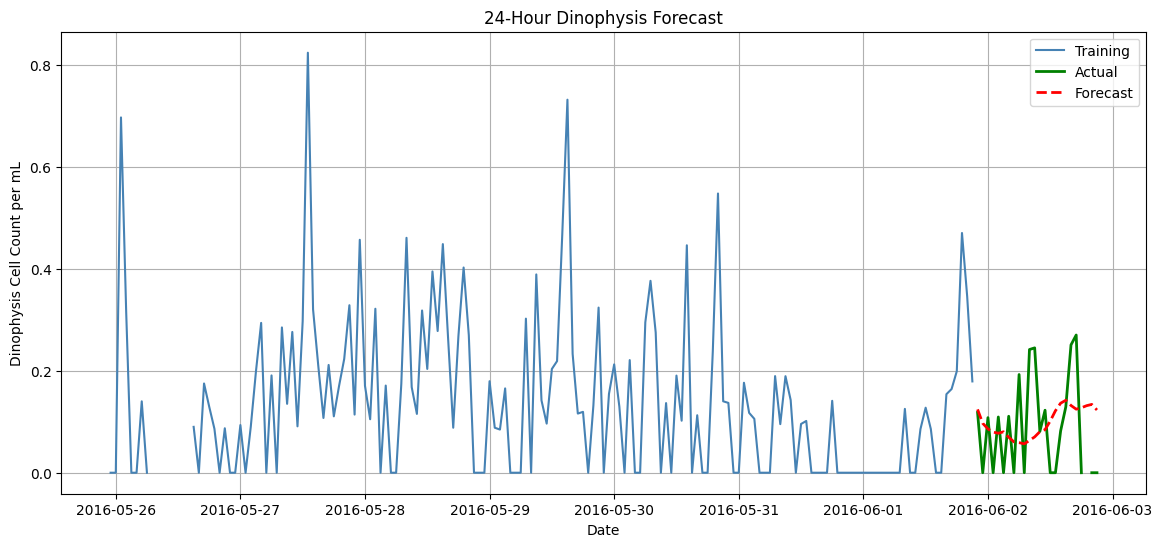

In [ ]:
plt.figure(figsize=(14,6))

# Last 7 days of training
plt.plot(
    context_df["timestamp"].iloc[-24*7:],
    context_df["target"].iloc[-24*7:],
    label="Training",
    color="steelblue"
)

# Actual last 24 hours
plt.plot(
    chronos_train["timestamp"].iloc[-24:],
    chronos_train["target"].iloc[-24:],
    label="Actual",
    color="green",
    linewidth=2
)

# Forecast
plt.plot(
    predictions_24h["timestamp"],
    predictions_24h["predictions"],
    label="Forecast",
    color="red",
    linewidth=2,
    linestyle="--"
)

plt.legend()
plt.grid(True)
plt.title("24-Hour Dinophysis Forecast")
plt.ylabel("Dinophysis Cell Count per mL")
plt.xlabel("Date")
plt.show()

Getting the metrics:

In [ ]:
# Making sure the indexes of actual and predicted rows match before doing comparisons
actual = chronos_train.iloc[-prediction_length:]["target"].reset_index(drop=True)
predicted = predictions_24h["predictions"].reset_index(drop=True)

mask = actual.notna()

actual_eval = actual[mask]
predicted_eval = predicted[mask]

from sklearn.metrics import mean_absolute_error
import numpy as np

# Doing the calculations
mae = mean_absolute_error(actual_eval, predicted_eval)
rmse = np.sqrt(((actual_eval - predicted_eval) ** 2).mean())

print("Number of evaluated observations:", len(actual_eval))
print("MAE:", mae)
print("RMSE:", rmse)

Number of evaluated observations: 23
MAE: 0.08429587436681432
RMSE: 0.09925721790541038


### 1-week forecast:

Setting up our data for 1-week forecast:



In [ ]:
# Tells the model how many steps ahead to forecast
prediction_length = 168

In [ ]:
# Doing train/test split
context_df = chronos_train.iloc[:-prediction_length].copy()
future_df = chronos_train.iloc[-prediction_length:].copy()

# Dropping the target column to avoid data leakage
future_df = future_df.drop(columns=["target"])

In [ ]:
# Generating the forecast and storing it into "predictions"
predictions_168h = pipeline.predict_df(
    df=context_df,
    future_df=future_df,
    id_column="item_id",
    timestamp_column="timestamp",
    target="target",
    prediction_length=prediction_length,
)

In [ ]:
# Making sure the dates/times match for predictions vs actual
print("Predictions:")
print(predictions_168h["timestamp"].head())
print(predictions_168h["timestamp"].tail())

print("\nActual:")
print(future_df["timestamp"].head())
print(future_df["timestamp"].tail())

Predictions:
0   2016-05-26 22:00:00
1   2016-05-26 23:00:00
2   2016-05-27 00:00:00
3   2016-05-27 01:00:00
4   2016-05-27 02:00:00
Name: timestamp, dtype: datetime64[ns]
163   2016-06-02 17:00:00
164   2016-06-02 18:00:00
165   2016-06-02 19:00:00
166   2016-06-02 20:00:00
167   2016-06-02 21:00:00
Name: timestamp, dtype: datetime64[ns]

Actual:
76401   2016-05-26 22:00:00
76402   2016-05-26 23:00:00
76403   2016-05-27 00:00:00
76404   2016-05-27 01:00:00
76405   2016-05-27 02:00:00
Name: timestamp, dtype: datetime64[ns]
76564   2016-06-02 17:00:00
76565   2016-06-02 18:00:00
76566   2016-06-02 19:00:00
76567   2016-06-02 20:00:00
76568   2016-06-02 21:00:00
Name: timestamp, dtype: datetime64[ns]


Plotting the results of 1-week forecast:

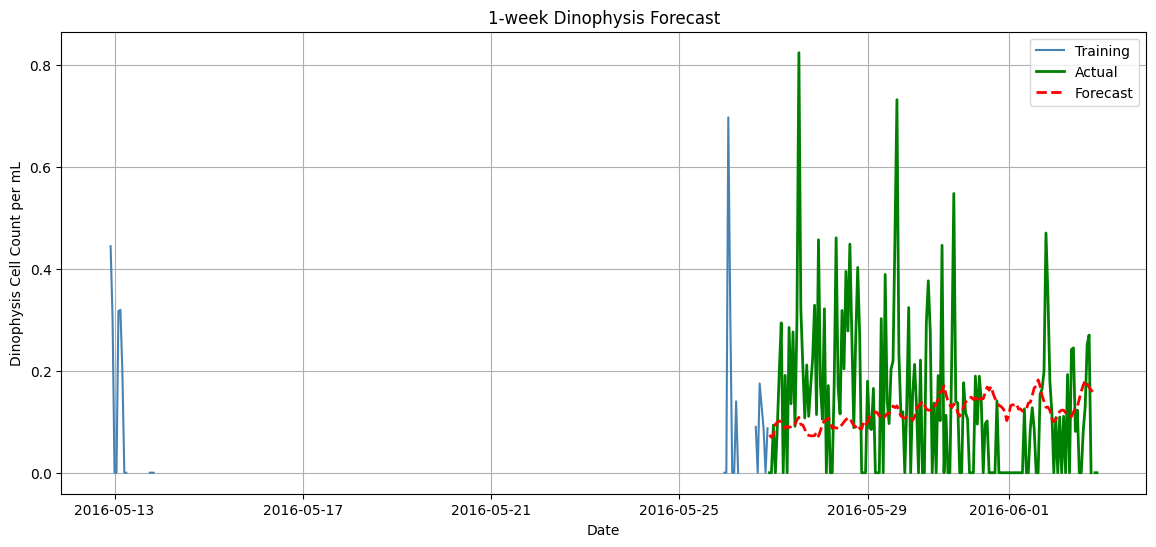

In [ ]:
plt.figure(figsize=(14,6))

# Last 2 weeks of training
plt.plot(
    context_df["timestamp"].iloc[-336:],
    context_df["target"].iloc[-336:],
    label="Training",
    color="steelblue"
)

# Actual last 168 hours (1 week)
plt.plot(
    chronos_train["timestamp"].iloc[-168:],
    chronos_train["target"].iloc[-168:],
    label="Actual",
    color="green",
    linewidth=2
)

# Forecast
plt.plot(
    predictions_168h["timestamp"],
    predictions_168h["predictions"],
    label="Forecast",
    color="red",
    linewidth=2,
    linestyle="--"
)

plt.legend()
plt.grid(True)
plt.title("1-week Dinophysis Forecast")
plt.ylabel("Dinophysis Cell Count per mL")
plt.xlabel("Date")
plt.show()

In [ ]:
forecast_start = predictions_168h["timestamp"].min()

two_weeks_before = forecast_start - pd.Timedelta(days=14)

history_plot = chronos_train[
    (chronos_train["timestamp"] >= two_weeks_before) &
    (chronos_train["timestamp"] < forecast_start)
]

In [ ]:
history_plot_clean = history_plot.dropna(subset=["target"])

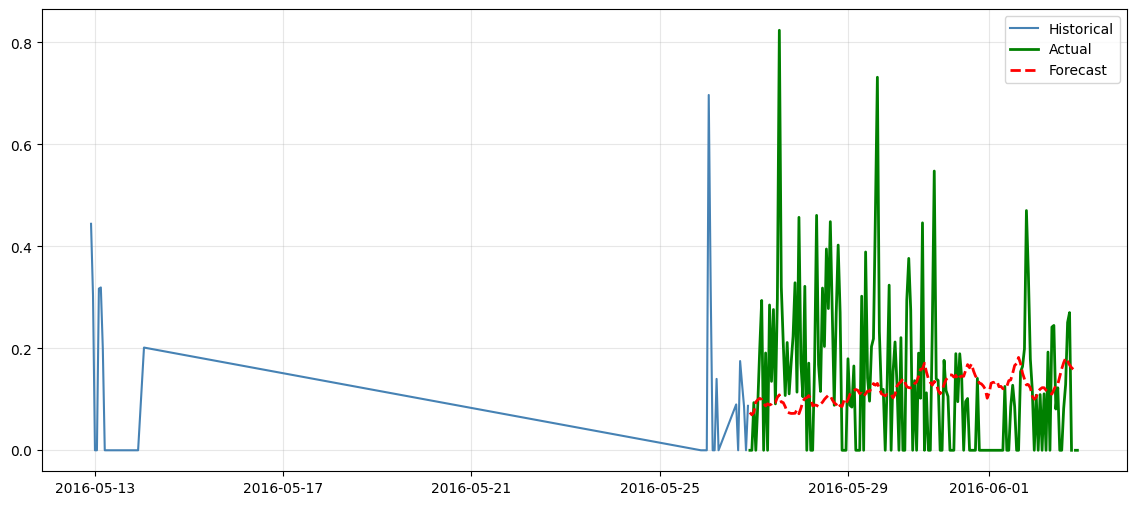

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(
    history_plot_clean["timestamp"],
    history_plot_clean["target"],
    label="Historical",
    color="steelblue"
)

plt.plot(
    chronos_train["timestamp"].iloc[-168:],
    chronos_train["target"].iloc[-168:],
    label="Actual",
    color="green",
    linewidth=2
)

plt.plot(
    predictions_168h["timestamp"],
    predictions_168h["predictions"],
    label="Forecast",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Getting the metrics for 1-week forecast:

In [ ]:
# Making sure the indexes of actual and predicted rows match before doing comparisons
actual = chronos_train.iloc[-prediction_length:]["target"].reset_index(drop=True)
predicted = predictions_168h["predictions"].reset_index(drop=True)

mask = actual.notna()

actual_eval = actual[mask]
predicted_eval = predicted[mask]

from sklearn.metrics import mean_absolute_error
import numpy as np

# Setting up calculations
mae = mean_absolute_error(actual_eval, predicted_eval)
rmse = np.sqrt(((actual_eval - predicted_eval) ** 2).mean())

print("Number of evaluated observations:", len(actual_eval))
print("MAE:", mae)
print("RMSE:", rmse)

Number of evaluated observations: 167
MAE: 0.11916060060675257
RMSE: 0.15633846082493158


### Setting up our data for 2-week forecast:

In [ ]:
# Tells the model how many steps ahead to forecast
prediction_length = 336

In [ ]:
# Doing train/test split
context_df = chronos_train.iloc[:-prediction_length].copy()
future_df = chronos_train.iloc[-prediction_length:].copy()

# Dropping the target column to avoid data leakage
future_df = future_df.drop(columns=["target"])

In [ ]:
# Generating the forecast and storing it into "predictions"
predictions_336h = pipeline.predict_df(
    df=context_df,
    future_df=future_df,
    id_column="item_id",
    timestamp_column="timestamp",
    target="target",
    prediction_length=prediction_length,
)

In [ ]:
# Making sure the dates/times match for predictions vs actual
print("Predictions:")
print(predictions_336h["timestamp"].head())
print(predictions_336h["timestamp"].tail())

print("\nActual:")
print(future_df["timestamp"].head())
print(future_df["timestamp"].tail())

Predictions:
0   2016-05-19 22:00:00
1   2016-05-19 23:00:00
2   2016-05-20 00:00:00
3   2016-05-20 01:00:00
4   2016-05-20 02:00:00
Name: timestamp, dtype: datetime64[ns]
331   2016-06-02 17:00:00
332   2016-06-02 18:00:00
333   2016-06-02 19:00:00
334   2016-06-02 20:00:00
335   2016-06-02 21:00:00
Name: timestamp, dtype: datetime64[ns]

Actual:
76233   2016-05-19 22:00:00
76234   2016-05-19 23:00:00
76235   2016-05-20 00:00:00
76236   2016-05-20 01:00:00
76237   2016-05-20 02:00:00
Name: timestamp, dtype: datetime64[ns]
76564   2016-06-02 17:00:00
76565   2016-06-02 18:00:00
76566   2016-06-02 19:00:00
76567   2016-06-02 20:00:00
76568   2016-06-02 21:00:00
Name: timestamp, dtype: datetime64[ns]


Plotting the results of 2-week forecast:

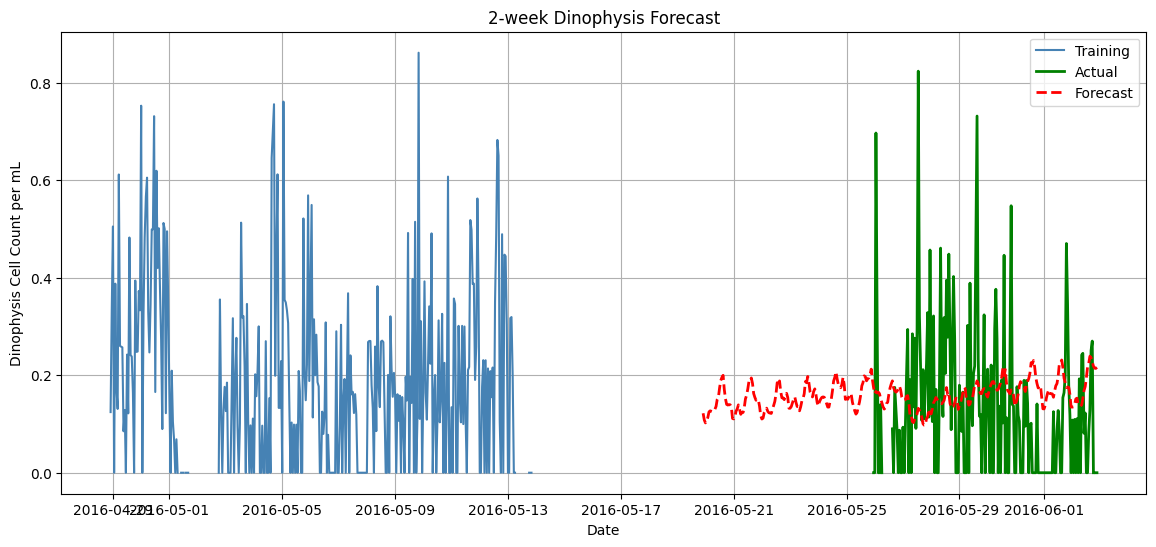

In [ ]:
plt.figure(figsize=(14,6))

# Last 3 weeks days of training
plt.plot(
    context_df["timestamp"].iloc[-504:],
    context_df["target"].iloc[-504:],
    label="Training",
    color="steelblue"
)

# Actual last 2-weeks
plt.plot(
    chronos_train["timestamp"].iloc[-336:],
    chronos_train["target"].iloc[-336:],
    label="Actual",
    color="green",
    linewidth=2
)

# Forecast
plt.plot(
    predictions_336h["timestamp"],
    predictions_336h["predictions"],
    label="Forecast",
    color="red",
    linewidth=2,
    linestyle="--"
)

plt.legend()
plt.grid(True)
plt.title("2-week Dinophysis Forecast")
plt.ylabel("Dinophysis Cell Count per mL")
plt.xlabel("Date")
plt.show()

Getting the metrics:

In [ ]:
# Making sure the indexes of actual and predicted rows match before doing comparisons
actual = chronos_train.iloc[-prediction_length:]["target"].reset_index(drop=True)
predicted = predictions_336h["predictions"].reset_index(drop=True)

mask = actual.notna()

actual_eval = actual[mask]
predicted_eval = predicted[mask]

from sklearn.metrics import mean_absolute_error
import numpy as np

# Setting up calculations
mae = mean_absolute_error(actual_eval, predicted_eval)
rmse = np.sqrt(((actual_eval - predicted_eval) ** 2).mean())

print("Number of evaluated observations:", len(actual_eval))
print("MAE:", mae)
print("RMSE:", rmse)

Number of evaluated observations: 183
MAE: 0.1291911003565716
RMSE: 0.16127555504916444


## Working with the Keras Time-Series Transformer

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import keras
from keras import layers

In [ ]:
# Loading our data into a url and creating a new dataframe specifically for the transformer
# NOTE: Access to the original dataset is limited
# you can use your own datset with url =""
keras_df = pd.read_csv(url, parse_dates=['Date'])

In [ ]:
keras_df = keras_df.rename(
    columns={"Date":"timestamp"}
)

keras_df = keras_df.sort_values("timestamp")

In [ ]:
keras_df.shape

(76569, 291)

In [ ]:
# Seeing which columns have the greatest amount of missing data
missing_percent = (keras_df.isna().sum() / len(keras_df)) * 100

missing_percent.sort_values(ascending=False).head(20)

,0
tabs_d_salinity_50,100.0
tabs_b_salinity_25,100.0
tabs_b_salinity_50,100.0
tabs_r_salinity_25,100.0
TIDE42045h,100.0
TIDE42044h,100.0
tabs_r_salinity_50,100.0
tabs_f_salinity_25,100.0
tabs_f_salinity_50,100.0
tabs_d_salinity_25,100.0


In [ ]:
# Extra data cleaning (removing all the variables that are missing 90% or more of data)
keep = int(len(keras_df) * 0.80)

keras_df = keras_df.dropna(axis = 1, thresh = keep)

keras_df.shape

(76569, 7)

In [ ]:
'''keras_df = keras_df[["Date", "Dinophysis"]].copy()

keras_df = keras_df.rename(
    columns={
        "Date":"timestamp",
        "Dinophysis":"target"
    }
)

keras_df = keras_df.sort_values("timestamp")

keras_df = keras_df.dropna(subset=["target"]).reset_index(drop=True)

values = keras_df["target"].values
'''

In [ ]:
# Making a constant to store all phytoplankton columns into one list
PHYTO_COLS = [
 'Asterionellopsis',
 'Ceratium',
 'Chaetoceros',
 'DactFragCeratul',
 'Dinophysis',
 'Myrionectarubra',
 'P_minimum',
 'P_texanum',
 'Prorocentrum']

PHYTO_COLS

In [ ]:
# Removing the NaNs from our dinophysis column
keras_df = keras_df.dropna(subset=["Dinophysis"])

KeyError: ['Dinophysis']

In [ ]:
features = keras_df.drop(columns=PHYTO_COLS + ["timestamp"])

target = keras_df["Dinophysis"].values

X_values = features.values

In [ ]:
def create_sequences(features, target, window_size):
    X = []
    y = []

    for i in range(len(features) - window_size):

        X.append(
            features[i:i+window_size]
        )

        y.append(
            target[i+window_size]
        )

    return np.array(X), np.array(y)

In [ ]:
window_size = 24

X, y = create_sequences(
    features.values,
    target,
    window_size
)

In [ ]:
print(X.shape)
print(y.shape)

print(np.isnan(X).sum())
print(np.isnan(y).sum())

(60771, 24, 14)
(60771,)
3090576
0


In [ ]:
print(np.isnan(features.values).mean())

0.15158436431567446


In [ ]:
print(features.shape)

(60795, 14)


In [ ]:
X = X.reshape(
    X.shape[0],
    X.shape[1],
    1
)

print(X.shape)

IndexError: tuple index out of range

In [ ]:
prediction_length = 24

split = len(X) - prediction_length

X_train = X[:split]
y_train = y[:split]

X_test = X[split:]
y_test = y[split:]

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(60747, 24, 1)
(24, 24, 1)
(60747,)
(24,)


In [ ]:
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):

    # Attention
    x = layers.MultiHeadAttention(
        key_dim=head_size,
        num_heads=num_heads,
        dropout=dropout
    )(inputs, inputs)

    x = layers.Dropout(dropout)(x)

    x = layers.LayerNormalization(
        epsilon=1e-6
    )(x)

    res = x + inputs

    # Feed-forward network
    x = layers.Conv1D(
        filters=ff_dim,
        kernel_size=1,
        activation="relu"
    )(res)

    x = layers.Dropout(dropout)(x)

    x = layers.Conv1D(
        filters=inputs.shape[-1],
        kernel_size=1
    )(x)

    x = layers.LayerNormalization(
        epsilon=1e-6
    )(x)

    return x + res

In [ ]:
def build_model(
    input_shape,
    head_size,
    num_heads,
    ff_dim,
    num_transformer_blocks,
    mlp_units,
    dropout=0,
    mlp_dropout=0,
):

    inputs = keras.Input(shape=input_shape)

    x = inputs

    for _ in range(num_transformer_blocks):
        x = transformer_encoder(
            x,
            head_size,
            num_heads,
            ff_dim,
            dropout
        )

    x = layers.GlobalAveragePooling1D(
        data_format="channels_last"
    )(x)

    for dim in mlp_units:
        x = layers.Dense(
            dim,
            activation="relu"
        )(x)

        x = layers.Dropout(
            mlp_dropout
        )(x)

    # forecasting output
    outputs = layers.Dense(1)(x)

    return keras.Model(inputs, outputs)

In [ ]:
input_shape = X_train.shape[1:]

model = build_model(
    input_shape,
    head_size=64,
    num_heads=4,
    ff_dim=64,
    num_transformer_blocks=2,
    mlp_units=[64],
    dropout=0.1,
    mlp_dropout=0.1,
)

In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 1)     │      1,793 │ input_layer_2[0]… │
│ (MultiHeadAttentio… │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 24, 1)     │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 1)     │          2 │ dropout_8[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 24, 1)     │          0 │ layer_normalizat… │
│                     │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 24, 64)    │        128 │ add_4[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 24, 64)    │          0 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 24, 1)     │         65 │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 1)     │          2 │ conv1d_5[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 24, 1)     │          0 │ layer_normalizat… │
│                     │                   │            │ add_4[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 1)     │      1,793 │ add_5[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_5[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 24, 1)     │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 1)     │          2 │ dropout_11[0][0]  │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 24, 1)     │          0 │ layer_normalizat… │
│                     │                   │            │ add_5[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 24, 64)    │        128 │ add_6[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 24, 64)    │          0 │ conv1d_6[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 24, 1)     │         65 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 1)     │          2 │ conv1d_7[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 24, 1)     │          0 │ layer_normalizat

 Total params: 4,173 (16.30 KB)

 Trainable params: 4,173 (16.30 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
1519/1519 ━━━━━━━━━━━━━━━━━━━━ 29s 11ms/step - loss: 5.1215 - mae: 0.4989 - val_loss: 0.0696 - val_mae: 0.1469
Epoch 2/20
1519/1519 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 4.7717 - mae: 0.4623 - val_loss: 0.0698 - val_mae: 0.1463
Epoch 3/20
1519/1519 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 4.6750 - mae: 0.4620 - val_loss: 0.0678 - val_mae: 0.1253
Epoch 4/20
1519/1519 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 4.7927 - mae: 0.4637 - val_loss: 0.0699 - val_mae: 0.1470
Epoch 5/20
1519/1519 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 4.7206 - mae: 0.4612 - val_loss: 0.0675 - val_mae: 0.1327
Epoch 6/20
1519/1519 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 4.8054 - mae: 0.4666 - val_loss: 0.0686 - val_mae: 0.1418
Epoch 7/20
1519/1519 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 4.7304 - mae: 0.4646 - val_loss: 0.0768 - val_mae: 0.1501
Epoch 8/20
1519/1519 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 4.6827 - mae: 0.4638 - val_loss: 0.0678 - val_mae: 0.1375
Epoch 9/20
1519/1519 ━━━━━━━━━━━━━━━━━

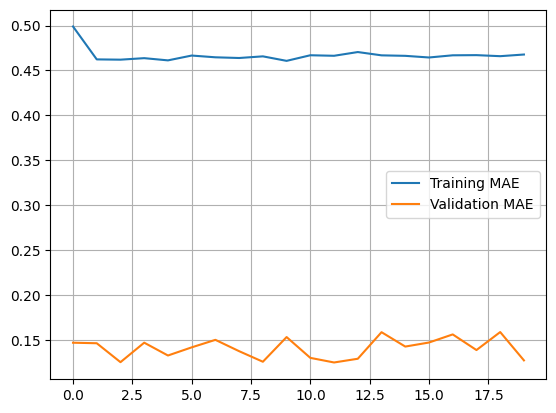

In [ ]:
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.legend()
plt.grid()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

keras_predictions = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    keras_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        keras_predictions
    )
)

r2 = r2_score(
    y_test,
    keras_predictions
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
MAE: 0.08158637614081192
RMSE: 0.09383067945832678
R²: -0.01067493438874334


In [ ]:
keras_predictions = model.predict(X_test)

keras_predictions = keras_predictions.flatten()

print(keras_predictions.shape)
print(y_test.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
(24,)
(24,)


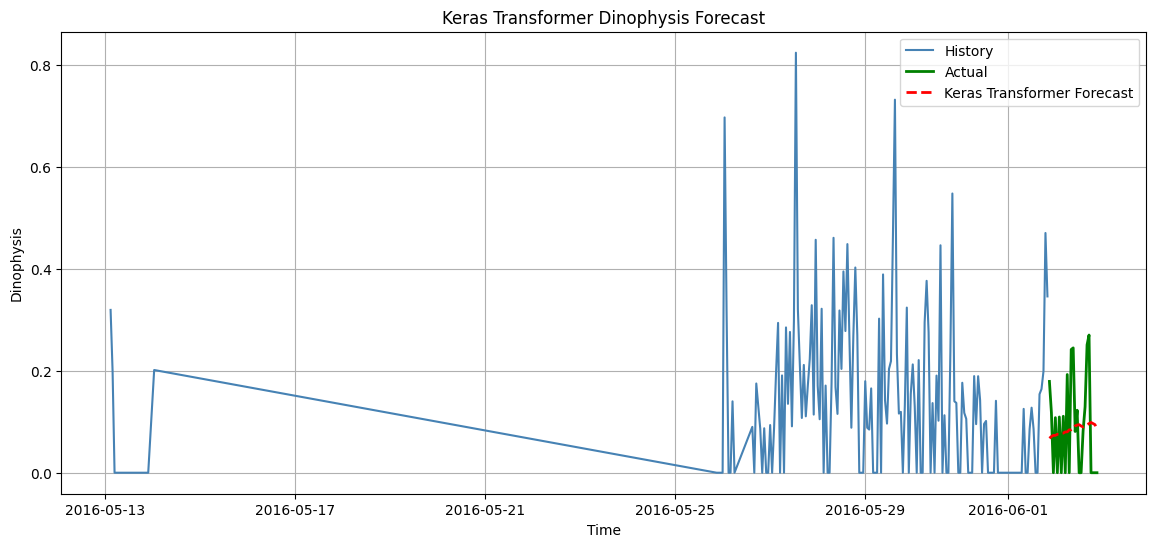

In [ ]:
plt.figure(figsize=(14,6))

# Previous history (last 7 days before prediction)
history_length = 24 * 7

plt.plot(
    keras_df["timestamp"].iloc[-prediction_length-history_length:-prediction_length],
    keras_df["target"].iloc[-prediction_length-history_length:-prediction_length],
    label="History",
    color="steelblue"
)

# Actual values
plt.plot(
    keras_df["timestamp"].iloc[-prediction_length:],
    y_test,
    label="Actual",
    color="green",
    linewidth=2
)

# Transformer predictions
plt.plot(
    keras_df["timestamp"].iloc[-prediction_length:],
    keras_predictions,
    label="Keras Transformer Forecast",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Keras Transformer Dinophysis Forecast")
plt.xlabel("Time")
plt.ylabel("Dinophysis")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
completeness = chronos_df.notna().mean().sort_values(ascending=False)
print(completeness.head(20))

### trying the keras transformer with a mask

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import keras
from keras import layers

In [ ]:
# Loading our data into a url and creating a new dataframe specifically for the transformer
# NOTE: Access to the original dataset is limited
# you can use your own datset with url =""
keras_df = pd.read_csv(url, parse_dates=['Date'])

In [ ]:
keras_df = keras_df.rename(
    columns={"Date":"timestamp"}
)

keras_df = keras_df.sort_values("timestamp")

In [ ]:
# Extra data cleaning (removing all the variables that are missing 90% or more of data)
keep = int(len(keras_df) * 0.10)

keras_df = keras_df.dropna(axis = 1, thresh = keep)

keras_df.shape

(76569, 208)

In [ ]:
# Making a constant to store all phytoplankton columns into one list
PHYTO_COLS = [
 'Asterionellopsis',
 'Ceratium',
 'Chaetoceros',
 'DactFragCeratul',
 'Dinophysis',
 'Myrionectarubra',
 'P_minimum',
 'P_texanum',
 'Prorocentrum']

PHYTO_COLS

['Asterionellopsis',
 'Ceratium',
 'Chaetoceros',
 'DactFragCeratul',
 'Dinophysis',
 'Myrionectarubra',
 'P_minimum',
 'P_texanum',
 'Prorocentrum']

In [ ]:
# Removing the NaNs from our dinophysis column
keras_df = keras_df.dropna(subset=["Dinophysis"])

In [ ]:
features = keras_df.drop(columns=PHYTO_COLS + ["timestamp"])

target = np.log1p(keras_df["Dinophysis"].values)

In [ ]:
feature_mask = (~features.isna()).astype(float)

In [ ]:
make_zero = features.fillna(0)

In [ ]:
X_values = make_zero.values
mask_values = feature_mask.values

In [ ]:
def create_sequences(features, mask, target, window_size):
    X = []
    X_mask = []
    y = []

    for i in range(len(features) - window_size):

        X.append(
            features[i:i+window_size]
        )

        X_mask.append(
            mask[i:i+window_size]
        )

        y.append(
            target[i+window_size]
        )

    return np.array(X), np.array(X_mask), np.array(y)

In [ ]:
window_size = 24

X, X_mask, y = create_sequences(
    X_values,
    mask_values,
    target,
    window_size
)

In [ ]:
X = X.astype("float32")
X_mask = X_mask.astype("float32")
y = y.astype("float32")

print(X.dtype)
print(X_mask.dtype)
print(y.dtype)

float32
float32
float32


In [ ]:
print(X.shape)
print(X_mask.shape)
print(y.shape)

(60771, 24, 198)
(60771, 24, 198)
(60771,)


In [ ]:
print(np.unique(X_mask))

[0. 1.]


In [ ]:
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):

    x = layers.MultiHeadAttention(
        key_dim=head_size,
        num_heads=num_heads,
        dropout=dropout
    )(inputs, inputs)

    x = layers.Dropout(dropout)(x)
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    res = x + inputs

    x = layers.Conv1D(
        filters=ff_dim,
        kernel_size=1,
        activation="relu"
    )(res)

    x = layers.Dropout(dropout)(x)

    x = layers.Conv1D(
        filters=inputs.shape[-1],
        kernel_size=1
    )(x)

    x = layers.LayerNormalization(epsilon=1e-6)(x)

    return x + res

In [ ]:
def build_model(
    input_shape,
    head_size,
    num_heads,
    ff_dim,
    num_transformer_blocks,
    mlp_units,
    dropout=0,
    mlp_dropout=0,
):

    data_input = keras.Input(
        shape=input_shape,
        name="data"
    )

    mask_input = keras.Input(
        shape=input_shape,
        name="mask"
    )

    # Combine measurements + missingness information
    x = layers.Concatenate()(
        [data_input, mask_input]
    )

    # Transformer blocks
    for _ in range(num_transformer_blocks):
        x = transformer_encoder(
            x,
            head_size,
            num_heads,
            ff_dim,
            dropout
        )

    # Pool time dimension
    x = layers.GlobalAveragePooling1D(
        data_format="channels_last"
    )(x)

    # Dense layers
    for dim in mlp_units:
        x = layers.Dense(
            dim,
            activation="relu"
        )(x)

        x = layers.Dropout(
            mlp_dropout
        )(x)

    # Regression output
    outputs = layers.Dense(1)(x)

    return keras.Model(
        inputs=[data_input, mask_input],
        outputs=outputs
    )

In [ ]:
input_shape = X.shape[1:]

model = build_model(
    input_shape=input_shape,
    head_size=32,
    num_heads=2,
    ff_dim=64,
    num_transformer_blocks=1,
    mlp_units=[64, 32],
    dropout=0.1,
    mlp_dropout=0.1,
)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ data (InputLayer)   │ (None, 24, 198)   │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask (InputLayer)   │ (None, 24, 198)   │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 24, 396)   │          0 │ data[0][0],       │
│ (Concatenate)       │                   │            │ mask[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 396)   │    101,964 │ concatenate[0][0… │
│ (MultiHeadAttentio… │                   │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 24, 396)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 24, 396)   │        792 │ dropout_1[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24, 396)   │          0 │ layer_normalizat… │
│                     │                   │            │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 24, 64)    │     25,408 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 24, 64)    │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 24, 396)   │     25,740 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 396)   │        792 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 24, 396)   │          0 │ layer_normalizat… │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 396)       │          0 │ add_1[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     25,408 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 182,217 (711.79 KB)

 Trainable params: 182,217 (711.79 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [ ]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_val = X[split:]

X_mask_train = X_mask[:split]
X_mask_val = X_mask[split:]

y_train = y[:split]
y_val = y[split:]

In [ ]:
print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_val.shape)

(48616, 24, 198)
(12155, 24, 198)
(48616,)
(12155,)


In [ ]:
history = model.fit(
    [X_train, X_mask_train],
    y_train,
    validation_data=(
        [X_val, X_mask_val],
        y_val
    ),
    epochs=20,
    batch_size=10
)

Epoch 1/20
4862/4862 ━━━━━━━━━━━━━━━━━━━━ 124s 24ms/step - loss: 31825520.0000 - mae: 1444.0188 - val_loss: 130055.2734 - val_mae: 158.9693
Epoch 2/20
4862/4862 ━━━━━━━━━━━━━━━━━━━━ 142s 24ms/step - loss: 10188.6572 - mae: 4.2041 - val_loss: 862.8184 - val_mae: 2.9484
Epoch 3/20
4862/4862 ━━━━━━━━━━━━━━━━━━━━ 135s 28ms/step - loss: 1353.6675 - mae: 0.9798 - val_loss: 0.9783 - val_mae: 0.2015
Epoch 4/20
4862/4862 ━━━━━━━━━━━━━━━━━━━━ 119s 25ms/step - loss: 327.9097 - mae: 0.4366 - val_loss: 0.0421 - val_mae: 0.1605
Epoch 5/20
4862/4862 ━━━━━━━━━━━━━━━━━━━━ 122s 25ms/step - loss: 2629.6174 - mae: 0.9007 - val_loss: 0.0654 - val_mae: 0.2250
Epoch 6/20
4862/4862 ━━━━━━━━━━━━━━━━━━━━ 120s 25ms/step - loss: 370.5447 - mae: 0.3988 - val_loss: 0.0794 - val_mae: 0.2542
Epoch 7/20
4862/4862 ━━━━━━━━━━━━━━━━━━━━ 119s 24ms/step - loss: 1452.2578 - mae: 0.6545 - val_loss: 0.0890 - val_mae: 0.2723
Epoch 8/20
4862/4862 ━━━━━━━━━━━━━━━━━━━━ 121s 25ms/step - loss: 4.4244 - mae: 0.3182 - val_loss: 0.073

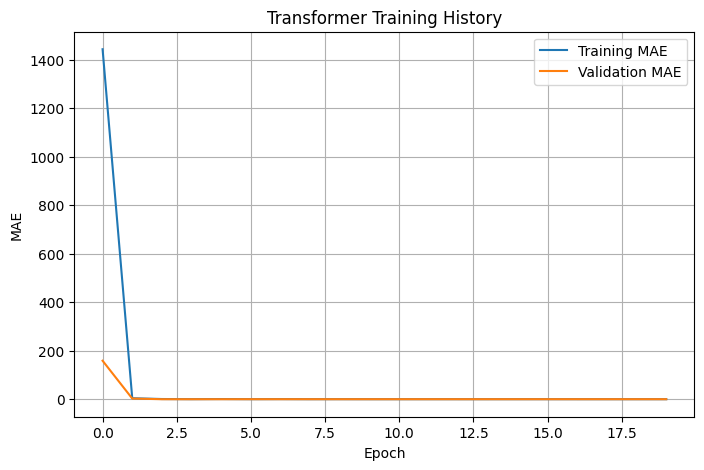

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Transformer Training History")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
y_pred = model.predict([X_val, X_mask_val])

y_pred = y_pred.flatten()

y_pred = np.expm1(y_pred)

380/380 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print(f"MAE :  {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"R²   :  {r2:.4f}")

MAE :  0.2934
RMSE:  0.3180
R²   :  -1.8244


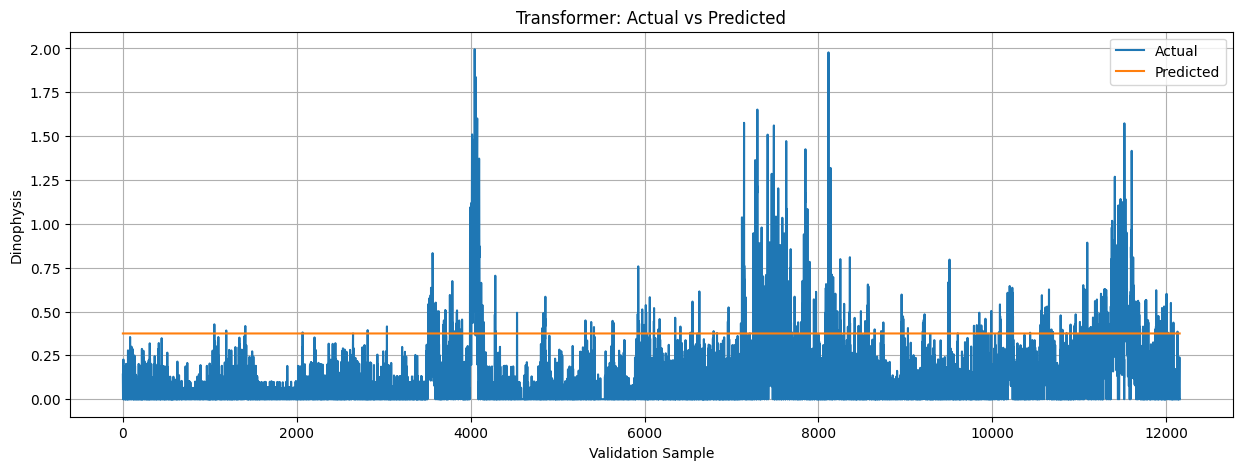

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(y_val, label="Actual")
plt.plot(y_pred, label="Predicted")

plt.title("Transformer: Actual vs Predicted")
plt.xlabel("Validation Sample")
plt.ylabel("Dinophysis")
plt.legend()
plt.grid(True)

plt.show()

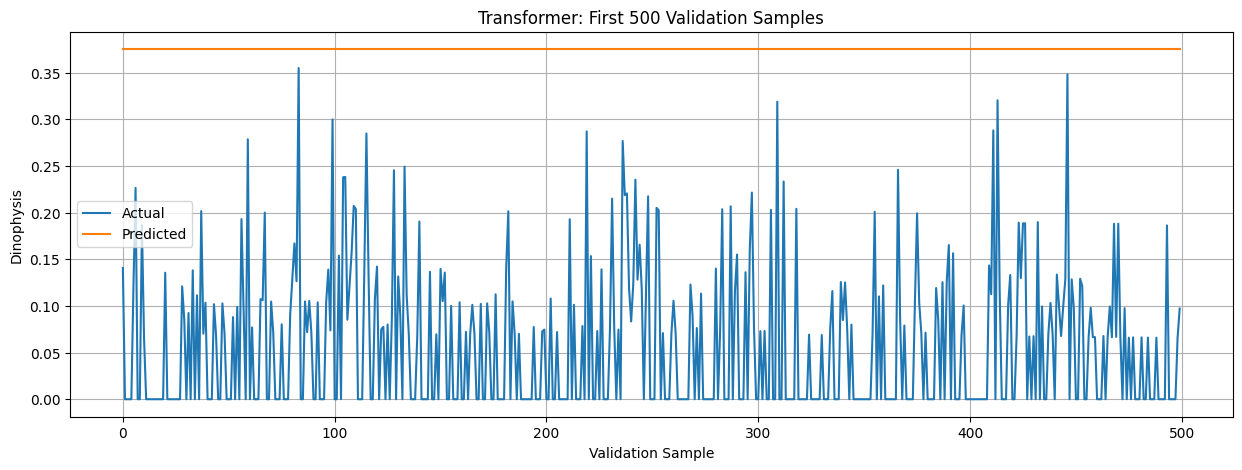

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(y_val[:500], label="Actual")
plt.plot(y_pred[:500], label="Predicted")

plt.title("Transformer: First 500 Validation Samples")
plt.xlabel("Validation Sample")
plt.ylabel("Dinophysis")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print("Predictions:")
print(pd.Series(y_pred).describe())

print("\nActual:")
print(pd.Series(y_val).describe())

Predictions:
count    12155.000000
mean         0.849519
std          0.000071
min          0.849519
25%          0.849519
50%          0.849519
75%          0.849519
max          0.849519
dtype: float64

Actual:
count    12155.000000
mean         0.152722
std          0.329319
min          0.000000
25%          0.000000
50%          0.072432
75%          0.175605
max          6.356669
dtype: float64


In [ ]:
print(pd.Series(y_train).describe())

count    48616.000000
mean         0.840037
std          3.821663
min          0.000000
25%          0.069718
50%          0.150397
75%          0.385440
max        140.475922
dtype: float64


In [ ]:
print(history.history["loss"][-1])
print(history.history["val_loss"][-1])

14.609098434448242
0.5939707159996033


In [ ]:
print(np.isnan(X_train).sum())
print(np.isnan(X_mask_train).sum())
print(np.isnan(y_train).sum())

0
0
0


## Making our 3 models with the Keras Transformer

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import keras
from keras import layers

In [ ]:
# Loading our data into a url and creating a new dataframe specifically for the transformer
# NOTE: Access to the original dataset is limited
# you can use your own datset with url =""
keras_df = pd.read_csv(url, parse_dates=['Date'])

In [ ]:
keras_df = keras_df.rename(
    columns={"Date":"timestamp"}
)

keras_df = keras_df.sort_values("timestamp")

In [ ]:
# Making our target variables
keras_df["target_24h"] = keras_df["Dinophysis"].shift(-24)

keras_df["target_168h"] = keras_df["Dinophysis"].shift(-168)

keras_df["target_336h"] = keras_df["Dinophysis"].shift(-336)

In [ ]:
# Making a constant to store all phytoplankton columns into one list
PHYTO_COLS = [
 'Asterionellopsis',
 'Ceratium',
 'Chaetoceros',
 'DactFragCeratul',
 'Dinophysis',
 'Myrionectarubra',
 'P_minimum',
 'P_texanum',
 'Prorocentrum']

PHYTO_COLS

['Asterionellopsis',
 'Ceratium',
 'Chaetoceros',
 'DactFragCeratul',
 'Dinophysis',
 'Myrionectarubra',
 'P_minimum',
 'P_texanum',
 'Prorocentrum']

In [ ]:
# Extra data cleaning (removing all the variables that are missing 90% or more of data)
keep = int(len(keras_df) * 0.50)

keras_df = keras_df.dropna(axis = 1, thresh = keep)

keras_df.shape

(76569, 57)

### 24 Hour forecast with keras transformer

In [ ]:
# Removing the NaNs from our dinophysis column
keras_24h = keras_df.dropna(subset=["target_24h"]).copy()

In [ ]:
features = keras_24h.drop(columns=PHYTO_COLS + ["timestamp", "target_24h", "target_168h", "target_336h"])

In [ ]:
features = features.fillna(features.mean(numeric_only=True))

In [ ]:
target = np.log1p(keras_24h["target_24h"].values)

In [ ]:
features.isna().sum()

,0
WDIR42046h,0
WSPD42046h,0
PWLVBOBHAL,0
ATMPBOBHAL,0
WSPDBOBHAL,0
WDIRBOBHAL,0
SALTMANER5,0
PHMANER5,0
DOMANER5,0
SATMANER5,0


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

features = pd.DataFrame(
    scaler.fit_transform(features),
    columns=features.columns,
    index=features.index
)

In [ ]:
X_values = features.values

In [ ]:
print(X_values.shape)
print(target.shape)

(60794, 44)
(60794,)


In [ ]:
def create_sequences(features, target, window_size):
    X = []
    y = []

    for i in range(len(features) - window_size):

        X.append(
            features[i:i+window_size]
        )

        y.append(
            target[i+window_size]
        )

    return np.array(X), np.array(y)

In [ ]:
window_size = 24

X, y = create_sequences(
    X_values,
    target,
    window_size
)

In [ ]:
X = X.astype("float32")
y = y.astype("float32")

print(X.dtype)
print(y.dtype)

float32
float32


In [ ]:
print(X.shape)
print(y.shape)

(60770, 24, 44)
(60770,)


In [ ]:
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):

    x = layers.MultiHeadAttention(
        key_dim=head_size,
        num_heads=num_heads,
        dropout=dropout
    )(inputs, inputs)

    x = layers.Dropout(dropout)(x)
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    res = x + inputs

    x = layers.Conv1D(
        filters=ff_dim,
        kernel_size=1,
        activation="relu"
    )(res)

    x = layers.Dropout(dropout)(x)

    x = layers.Conv1D(
        filters=inputs.shape[-1],
        kernel_size=1
    )(x)

    x = layers.LayerNormalization(epsilon=1e-6)(x)

    return x + res

In [ ]:
def build_model(
    input_shape,
    head_size,
    num_heads,
    ff_dim,
    num_transformer_blocks,
    mlp_units,
    dropout=0,
    mlp_dropout=0,
):

    data_input = keras.Input(
        shape=input_shape,
        name="data"
    )

    x = data_input

    # Transformer blocks
    for _ in range(num_transformer_blocks):
        x = transformer_encoder(
            x,
            head_size,
            num_heads,
            ff_dim,
            dropout
        )

    # Pool time dimension
    x = layers.GlobalAveragePooling1D(
        data_format="channels_last"
    )(x)

    # Dense layers
    for dim in mlp_units:
        x = layers.Dense(
            dim,
            activation="relu"
        )(x)

        x = layers.Dropout(
            mlp_dropout
        )(x)

    # Regression output
    outputs = layers.Dense(1)(x)

    return keras.Model(
        inputs=data_input,
        outputs=outputs
    )

In [ ]:
input_shape = X.shape[1:]

model = build_model(
    input_shape=input_shape,
    head_size=32,
    num_heads=2,
    ff_dim=64,
    num_transformer_blocks=1,
    mlp_units=[64, 32],
    dropout=0.1,
    mlp_dropout=0.1,
)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ data (InputLayer)   │ (None, 24, 44)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 44)    │     11,500 │ data[0][0],       │
│ (MultiHeadAttentio… │                   │            │ data[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 24, 44)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 24, 44)    │         88 │ dropout_1[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24, 44)    │          0 │ layer_normalizat… │
│                     │                   │            │ data[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 24, 64)    │      2,880 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 24, 64)    │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 24, 44)    │      2,860 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 44)    │         88 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 24, 44)    │          0 │ layer_normalizat… │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 44)        │          0 │ add_1[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      2,880 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 22,409 (87.54 KB)

 Trainable params: 22,409 (87.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [ ]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_val = X[split:]

y_train = y[:split]
y_val = y[split:]

In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=20,
    batch_size=8
)

Epoch 1/20
6077/6077 ━━━━━━━━━━━━━━━━━━━━ 44s 6ms/step - loss: 0.2166 - mae: 0.2679 - val_loss: 0.0496 - val_mae: 0.1791
Epoch 2/20
6077/6077 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - loss: 0.1745 - mae: 0.2454 - val_loss: 0.0525 - val_mae: 0.1910
Epoch 3/20
6077/6077 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - loss: 0.1563 - mae: 0.2345 - val_loss: 0.0536 - val_mae: 0.1849
Epoch 4/20
6077/6077 ━━━━━━━━━━━━━━━━━━━━ 41s 7ms/step - loss: 0.1453 - mae: 0.2261 - val_loss: 0.0501 - val_mae: 0.1745
Epoch 5/20
6077/6077 ━━━━━━━━━━━━━━━━━━━━ 42s 7ms/step - loss: 0.1344 - mae: 0.2176 - val_loss: 0.0706 - val_mae: 0.2063
Epoch 6/20
6077/6077 ━━━━━━━━━━━━━━━━━━━━ 41s 7ms/step - loss: 0.1207 - mae: 0.2078 - val_loss: 0.0434 - val_mae: 0.1380
Epoch 7/20
6077/6077 ━━━━━━━━━━━━━━━━━━━━ 80s 6ms/step - loss: 0.1125 - mae: 0.2015 - val_loss: 0.0414 - val_mae: 0.1503
Epoch 8/20
6077/6077 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - loss: 0.1042 - mae: 0.1961 - val_loss: 0.0473 - val_mae: 0.1535
Epoch 9/20
6077/6077 ━━━━━━━━━━━

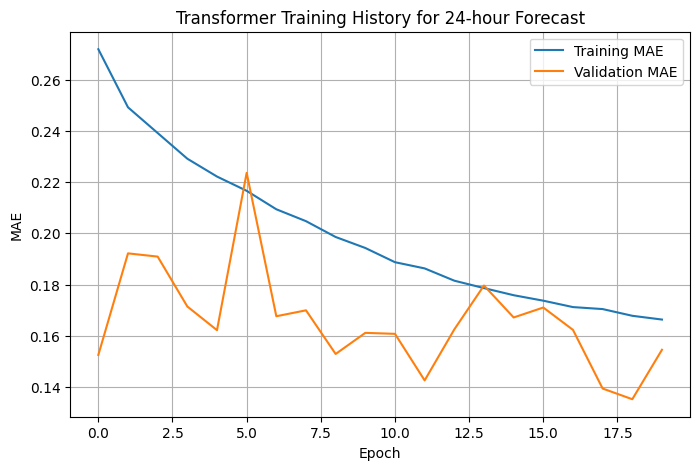

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Transformer Training History for 24-hour Forecast")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
y_pred = model.predict(X_val)

y_pred = y_pred.flatten()

y_pred = np.expm1(y_pred)

380/380 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print(f"MAE :  {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"R²   :  {r2:.4f}")

MAE :  0.1671
RMSE:  0.3736
R²   :  -2.9001


In [ ]:
print("Predictions:")
print(pd.Series(y_pred).describe())

print("\nActual:")
print(pd.Series(y_val).describe())

Predictions:
count    12154.000000
mean         0.207081
std          0.676197
min         -0.061115
25%          0.100183
50%          0.155273
75%          0.174261
max         17.228668
dtype: float64

Actual:
count    12154.000000
mean         0.119399
std          0.189203
min          0.000000
25%          0.000000
50%          0.069914
75%          0.161797
max          1.995607
dtype: float64


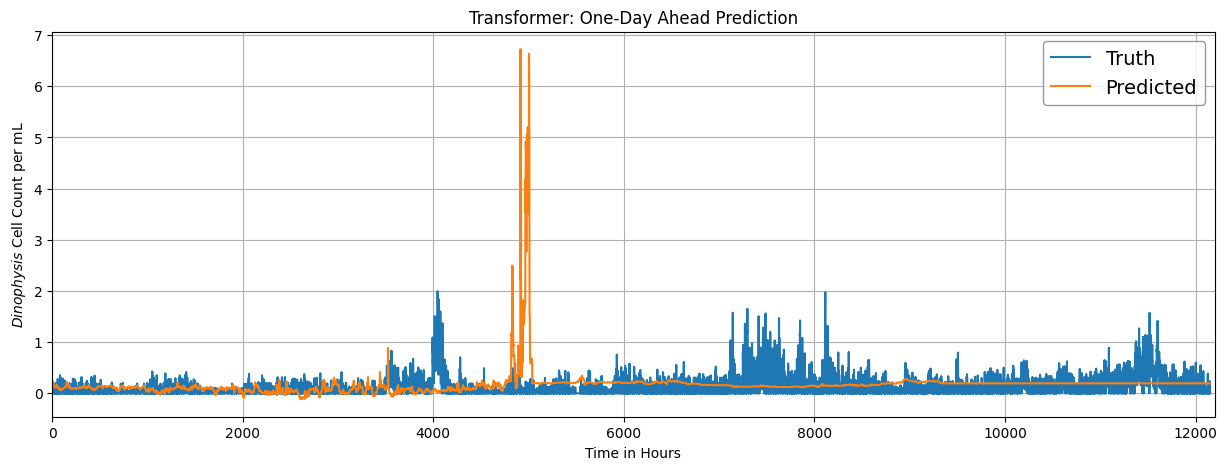

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(y_val, label="Truth")
plt.plot(y_pred, label="Predicted")

plt.title("Transformer: One-Day Ahead Prediction")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.legend(fontsize=14, edgecolor='gray')
plt.xlim(0,12200)
plt.grid(True)

plt.show()

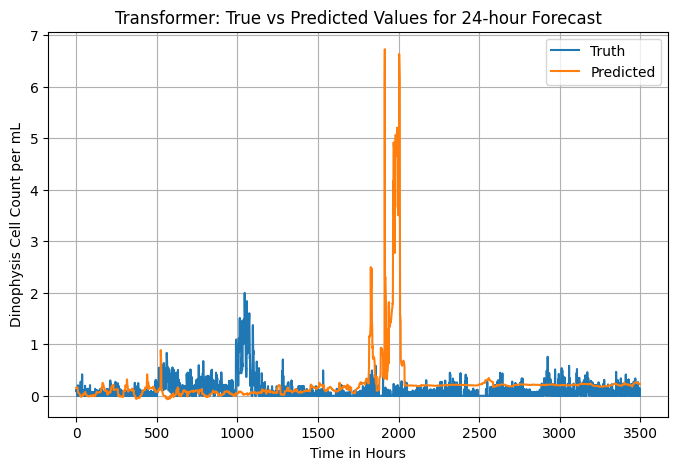

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(y_val[3000:6500], label="Truth")
plt.plot(y_pred[3000:6500], label="Predicted")

plt.title("Transformer: True vs Predicted Values for 24-hour Forecast")
plt.xlabel("Time in Hours")
plt.ylabel("Dinophysis Cell Count per mL")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
y_train_pred = model.predict(X_train)

y_train_pred = y_train_pred.flatten()

# Convert back from log scale
y_train_pred = np.expm1(y_train_pred)
y_train_true = np.expm1(y_train)

1520/1520 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step


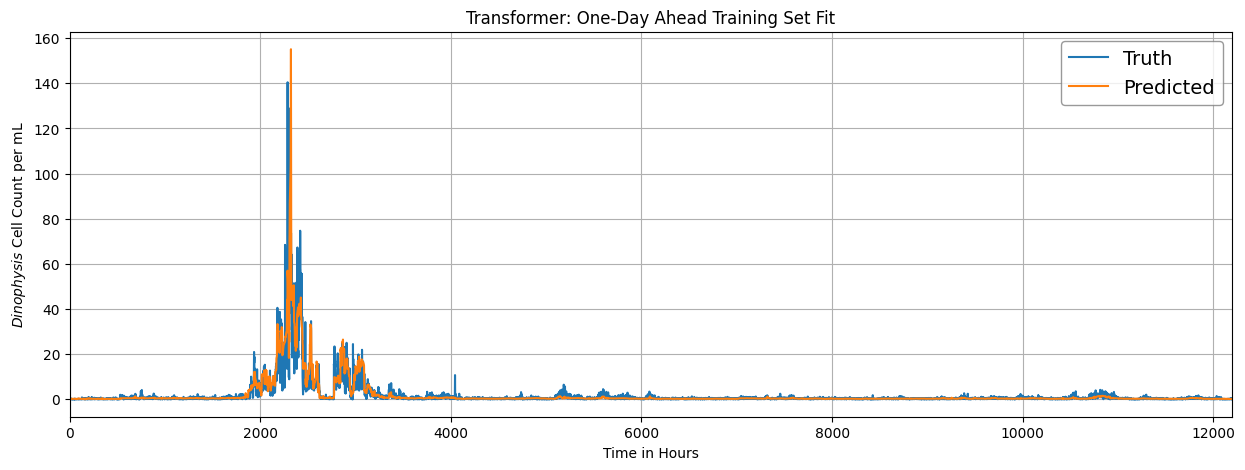

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(y_train_true, label="Truth")
plt.plot(y_train_pred, label="Predicted")

plt.title("Transformer: One-Day Ahead Training Set Fit")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.xlim(0,12200)
plt.legend(fontsize=14, edgecolor='gray')
plt.grid(True)

plt.show()

### 1-Week forecast with keras transformer

In [ ]:
# Removing the NaNs from our dinophysis column
keras_168h = keras_df.dropna(subset=["target_168h"]).copy()

In [ ]:
features = keras_168h.drop(columns=PHYTO_COLS + ["timestamp", "target_24h", "target_168h", "target_336h"])

In [ ]:
features = features.fillna(features.mean(numeric_only=True))

In [ ]:
target = np.log1p(keras_168h["target_168h"].values)

In [ ]:
features.isna().sum()

,0
WDIR42046h,0
WSPD42046h,0
PWLVBOBHAL,0
ATMPBOBHAL,0
WSPDBOBHAL,0
WDIRBOBHAL,0
SALTMANER5,0
PHMANER5,0
DOMANER5,0
SATMANER5,0


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

features = pd.DataFrame(
    scaler.fit_transform(features),
    columns=features.columns,
    index=features.index
)

In [ ]:
X_values = features.values

In [ ]:
print(X_values.shape)
print(target.shape)

(60729, 44)
(60729,)


In [ ]:
def create_sequences(features, target, window_size):
    X = []
    y = []

    for i in range(len(features) - window_size):

        X.append(
            features[i:i+window_size]
        )

        y.append(
            target[i+window_size]
        )

    return np.array(X), np.array(y)

In [ ]:
window_size = 24

X, y = create_sequences(
    X_values,
    target,
    window_size
)

In [ ]:
X = X.astype("float32")
y = y.astype("float32")

print(X.dtype)
print(y.dtype)

float32
float32


In [ ]:
print(X.shape)
print(y.shape)

(60705, 24, 44)
(60705,)


In [ ]:
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):

    x = layers.MultiHeadAttention(
        key_dim=head_size,
        num_heads=num_heads,
        dropout=dropout
    )(inputs, inputs)

    x = layers.Dropout(dropout)(x)
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    res = x + inputs

    x = layers.Conv1D(
        filters=ff_dim,
        kernel_size=1,
        activation="relu"
    )(res)

    x = layers.Dropout(dropout)(x)

    x = layers.Conv1D(
        filters=inputs.shape[-1],
        kernel_size=1
    )(x)

    x = layers.LayerNormalization(epsilon=1e-6)(x)

    return x + res

In [ ]:
def build_model(
    input_shape,
    head_size,
    num_heads,
    ff_dim,
    num_transformer_blocks,
    mlp_units,
    dropout=0,
    mlp_dropout=0,
):

    data_input = keras.Input(
        shape=input_shape,
        name="data"
    )

    x = data_input

    # Transformer blocks
    for _ in range(num_transformer_blocks):
        x = transformer_encoder(
            x,
            head_size,
            num_heads,
            ff_dim,
            dropout
        )

    # Pool time dimension
    x = layers.GlobalAveragePooling1D(
        data_format="channels_last"
    )(x)

    # Dense layers
    for dim in mlp_units:
        x = layers.Dense(
            dim,
            activation="relu"
        )(x)

        x = layers.Dropout(
            mlp_dropout
        )(x)

    # Regression output
    outputs = layers.Dense(1)(x)

    return keras.Model(
        inputs=data_input,
        outputs=outputs
    )

In [ ]:
input_shape = X.shape[1:]

model = build_model(
    input_shape=input_shape,
    head_size=32,
    num_heads=2,
    ff_dim=64,
    num_transformer_blocks=1,
    mlp_units=[64, 32],
    dropout=0.1,
    mlp_dropout=0.1,
)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ data (InputLayer)   │ (None, 24, 44)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 44)    │     11,500 │ data[0][0],       │
│ (MultiHeadAttentio… │                   │            │ data[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 24, 44)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 24, 44)    │         88 │ dropout_1[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24, 44)    │          0 │ layer_normalizat… │
│                     │                   │            │ data[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 24, 64)    │      2,880 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 24, 64)    │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 24, 44)    │      2,860 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 44)    │         88 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 24, 44)    │          0 │ layer_normalizat… │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 44)        │          0 │ add_1[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      2,880 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 22,409 (87.54 KB)

 Trainable params: 22,409 (87.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [ ]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_val = X[split:]

y_train = y[:split]
y_val = y[split:]

In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=20,
    batch_size=8
)

Epoch 1/20
6071/6071 ━━━━━━━━━━━━━━━━━━━━ 64s 10ms/step - loss: 0.2158 - mae: 0.2689 - val_loss: 0.0602 - val_mae: 0.2129
Epoch 2/20
6071/6071 ━━━━━━━━━━━━━━━━━━━━ 86s 10ms/step - loss: 0.1788 - mae: 0.2484 - val_loss: 0.0451 - val_mae: 0.1617
Epoch 3/20
6071/6071 ━━━━━━━━━━━━━━━━━━━━ 59s 10ms/step - loss: 0.1619 - mae: 0.2373 - val_loss: 0.0608 - val_mae: 0.2097
Epoch 4/20
6071/6071 ━━━━━━━━━━━━━━━━━━━━ 83s 10ms/step - loss: 0.1491 - mae: 0.2288 - val_loss: 0.0486 - val_mae: 0.1553
Epoch 5/20
6071/6071 ━━━━━━━━━━━━━━━━━━━━ 59s 10ms/step - loss: 0.1373 - mae: 0.2208 - val_loss: 0.0780 - val_mae: 0.2058
Epoch 6/20
6071/6071 ━━━━━━━━━━━━━━━━━━━━ 58s 10ms/step - loss: 0.1284 - mae: 0.2155 - val_loss: 0.0878 - val_mae: 0.2046
Epoch 7/20
6071/6071 ━━━━━━━━━━━━━━━━━━━━ 59s 10ms/step - loss: 0.1224 - mae: 0.2108 - val_loss: 0.0552 - val_mae: 0.1675
Epoch 8/20
6071/6071 ━━━━━━━━━━━━━━━━━━━━ 61s 10ms/step - loss: 0.1150 - mae: 0.2060 - val_loss: 0.0726 - val_mae: 0.2009
Epoch 9/20
6071/6071 ━━━

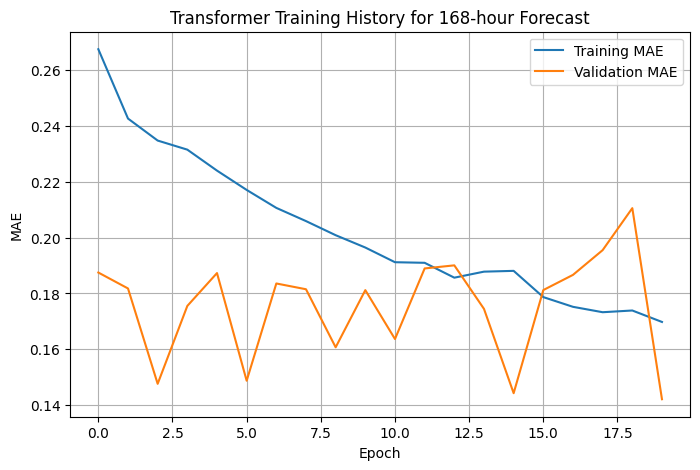

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Transformer Training History for 168-hour Forecast")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
y_pred = model.predict(X_val)

y_pred = y_pred.flatten()

y_pred = np.expm1(y_pred)

380/380 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print(f"MAE :  {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"R²   :  {r2:.4f}")

MAE :  0.2607
RMSE:  0.3882
R²   :  -3.2073


In [ ]:
print("Predictions:")
print(pd.Series(y_pred).describe())

print("\nActual:")
print(pd.Series(y_val).describe())

Predictions:
count    12141.000000
mean         0.326925
std          0.277118
min          0.049740
25%          0.183925
50%          0.242685
75%          0.461368
max          4.219426
dtype: float64

Actual:
count    12141.000000
mean         0.119477
std          0.189281
min          0.000000
25%          0.000000
50%          0.069993
75%          0.161936
max          1.995607
dtype: float64


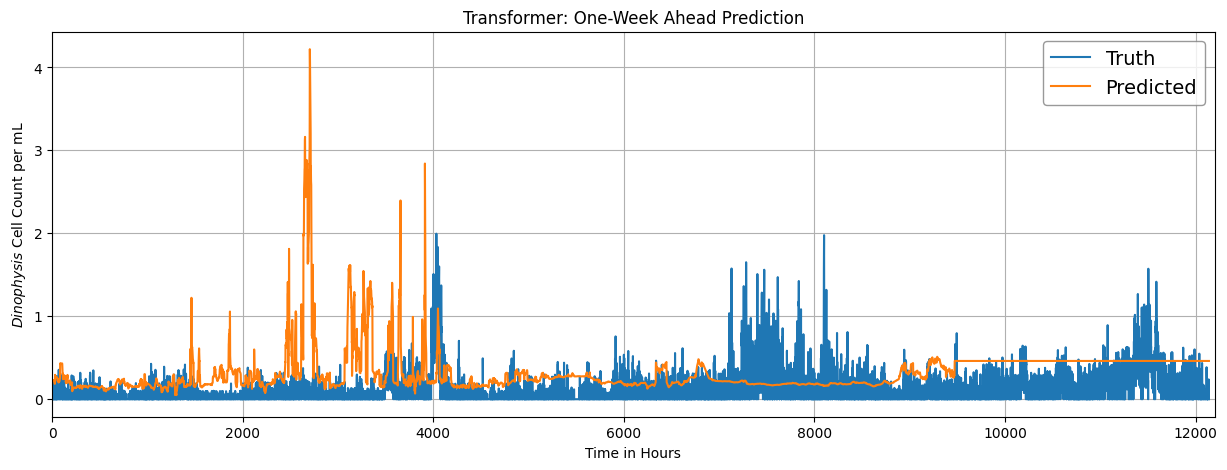

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(y_val, label="Truth")
plt.plot(y_pred, label="Predicted")

plt.title("Transformer: One-Week Ahead Prediction")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.xlim(0,12200)
plt.legend(fontsize=14, edgecolor='gray')
plt.grid(True)

plt.show()

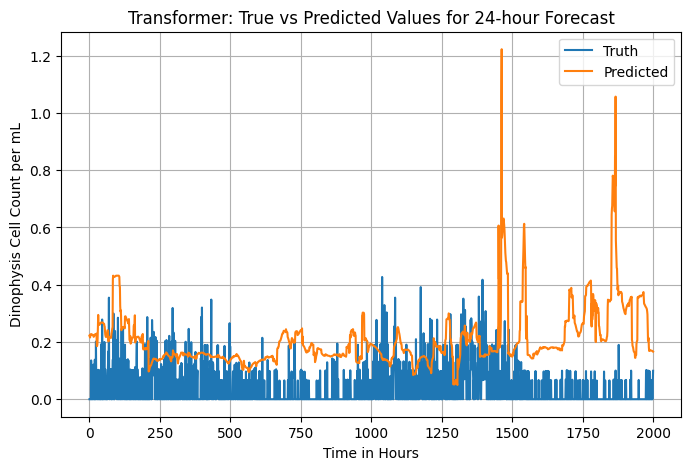

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(y_val[0:2000], label="Truth")
plt.plot(y_pred[0:2000], label="Predicted")

plt.title("Transformer: True vs Predicted Values for 24-hour Forecast")
plt.xlabel("Time in Hours")
plt.ylabel("Dinophysis Cell Count per mL")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
y_train_pred = model.predict(X_train)

y_train_pred = y_train_pred.flatten()

# Convert back from log scale
y_train_pred = np.expm1(y_train_pred)
y_train_true = np.expm1(y_train)

1518/1518 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step


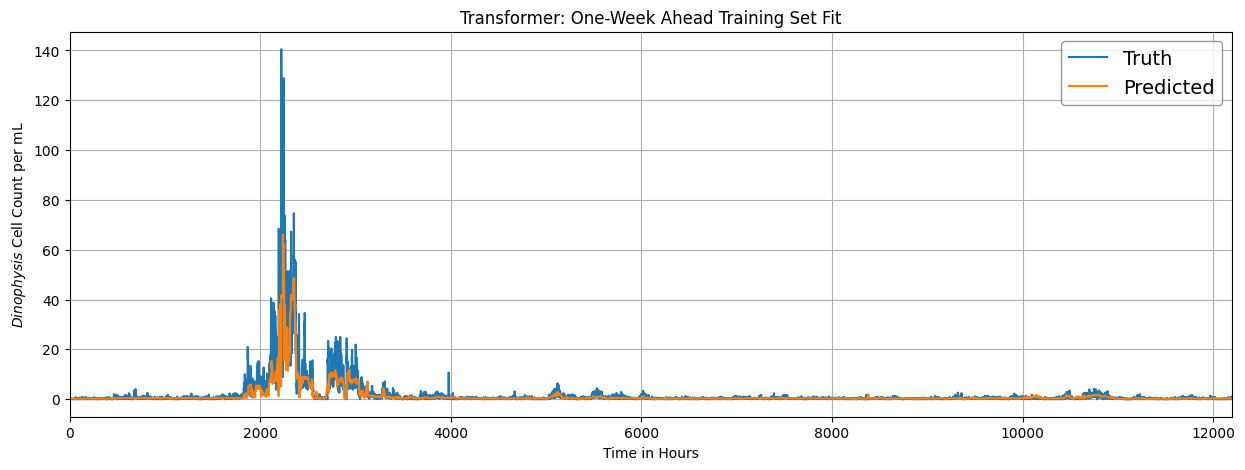

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(y_train_true, label="Truth")
plt.plot(y_train_pred, label="Predicted")

plt.title("Transformer: One-Week Ahead Training Set Fit")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.legend(fontsize=14, edgecolor='gray')
plt.xlim(0,12200)
plt.grid(True)

plt.show()

### 2-Week forecast with keras transformer

In [ ]:
# Removing the NaNs from our dinophysis column
keras_336h = keras_df.dropna(subset=["target_336h"]).copy()

In [ ]:
features = keras_336h.drop(columns=PHYTO_COLS + ["timestamp", "target_24h", "target_168h", "target_336h"])

In [ ]:
features = features.fillna(features.mean(numeric_only=True))

In [ ]:
target = np.log1p(keras_336h["target_336h"].values)

In [ ]:
features.isna().sum()

,0
WDIR42046h,0
WSPD42046h,0
PWLVBOBHAL,0
ATMPBOBHAL,0
WSPDBOBHAL,0
WDIRBOBHAL,0
SALTMANER5,0
PHMANER5,0
DOMANER5,0
SATMANER5,0


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

features = pd.DataFrame(
    scaler.fit_transform(features),
    columns=features.columns,
    index=features.index
)

In [ ]:
X_values = features.values

In [ ]:
print(X_values.shape)
print(target.shape)

(60646, 44)
(60646,)


In [ ]:
def create_sequences(features, target, window_size):
    X = []
    y = []

    for i in range(len(features) - window_size):

        X.append(
            features[i:i+window_size]
        )

        y.append(
            target[i+window_size]
        )

    return np.array(X), np.array(y)

In [ ]:
window_size = 24

X, y = create_sequences(
    X_values,
    target,
    window_size
)

In [ ]:
X = X.astype("float32")
y = y.astype("float32")

print(X.dtype)
print(y.dtype)

float32
float32


In [ ]:
print(X.shape)
print(y.shape)

(60622, 24, 44)
(60622,)


In [ ]:
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):

    x = layers.MultiHeadAttention(
        key_dim=head_size,
        num_heads=num_heads,
        dropout=dropout
    )(inputs, inputs)

    x = layers.Dropout(dropout)(x)
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    res = x + inputs

    x = layers.Conv1D(
        filters=ff_dim,
        kernel_size=1,
        activation="relu"
    )(res)

    x = layers.Dropout(dropout)(x)

    x = layers.Conv1D(
        filters=inputs.shape[-1],
        kernel_size=1
    )(x)

    x = layers.LayerNormalization(epsilon=1e-6)(x)

    return x + res

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ data (InputLayer)   │ (None, 24, 44)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 24, 44)    │     11,500 │ data[0][0],       │
│ (MultiHeadAttentio… │                   │            │ data[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 24, 44)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 24, 44)    │         88 │ dropout_1[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24, 44)    │          0 │ layer_normalizat… │
│                     │                   │            │ data[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 24, 64)    │      2,880 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 24, 64)    │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 24, 44)    │      2,860 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 24, 44)    │         88 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 24, 44)    │          0 │ layer_normalizat… │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 44)        │          0 │ add_1[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      2,880 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 67,229 (262.62 KB)

 Trainable params: 22,409 (87.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 44,820 (175.08 KB)

In [ ]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [ ]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_val = X[split:]

y_train = y[:split]
y_val = y[split:]

In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=20,
    batch_size=8
)

Epoch 1/20
6063/6063 ━━━━━━━━━━━━━━━━━━━━ 69s 11ms/step - loss: 0.1275 - mae: 0.2116 - val_loss: 0.0581 - val_mae: 0.1763
Epoch 2/20
6063/6063 ━━━━━━━━━━━━━━━━━━━━ 64s 11ms/step - loss: 0.0999 - mae: 0.1928 - val_loss: 0.0443 - val_mae: 0.1508
Epoch 3/20
6063/6063 ━━━━━━━━━━━━━━━━━━━━ 59s 10ms/step - loss: 0.0868 - mae: 0.1836 - val_loss: 0.0679 - val_mae: 0.1845
Epoch 4/20
6063/6063 ━━━━━━━━━━━━━━━━━━━━ 58s 10ms/step - loss: 0.0742 - mae: 0.1739 - val_loss: 0.2085 - val_mae: 0.2971
Epoch 5/20
6063/6063 ━━━━━━━━━━━━━━━━━━━━ 86s 10ms/step - loss: 0.0689 - mae: 0.1688 - val_loss: 0.0444 - val_mae: 0.1480
Epoch 6/20
6063/6063 ━━━━━━━━━━━━━━━━━━━━ 60s 10ms/step - loss: 0.0645 - mae: 0.1648 - val_loss: 0.0707 - val_mae: 0.2019
Epoch 7/20
6063/6063 ━━━━━━━━━━━━━━━━━━━━ 81s 10ms/step - loss: 0.0603 - mae: 0.1616 - val_loss: 0.0757 - val_mae: 0.2087
Epoch 8/20
6063/6063 ━━━━━━━━━━━━━━━━━━━━ 60s 10ms/step - loss: 0.0590 - mae: 0.1600 - val_loss: 0.4046 - val_mae: 0.4002
Epoch 9/20
6063/6063 ━━━

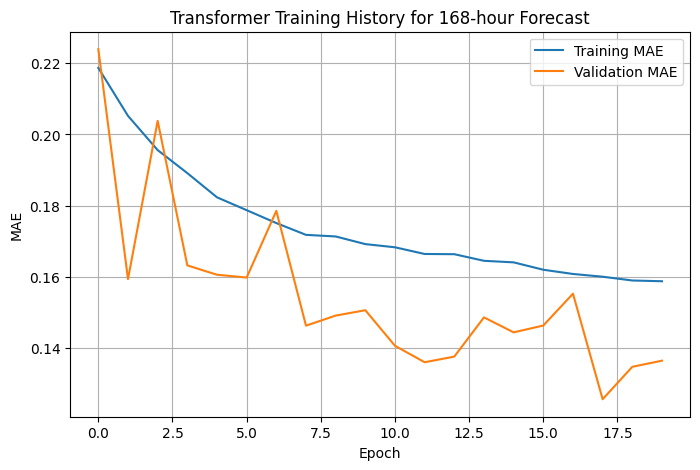

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Transformer Training History for 336-hour Forecast")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
y_pred = model.predict(X_val)

y_pred = y_pred.flatten()

y_pred = np.expm1(y_pred)

379/379 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step


In [ ]:
print("Predictions:")
print(pd.Series(y_pred).describe())

print("\nActual:")
print(pd.Series(y_val).describe())

Predictions:
count    12125.000000
mean         1.039921
std          1.572088
min          0.049555
25%          0.147655
50%          0.208438
75%          0.404071
max          4.812842
dtype: float64

Actual:
count    12125.000000
mean         0.119607
std          0.189365
min          0.000000
25%          0.000000
50%          0.070125
75%          0.162092
max          1.995607
dtype: float64


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print(f"MAE :  {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"R²   :  {r2:.4f}")

MAE :  0.9762
RMSE:  1.7994
R²   :  -89.3064


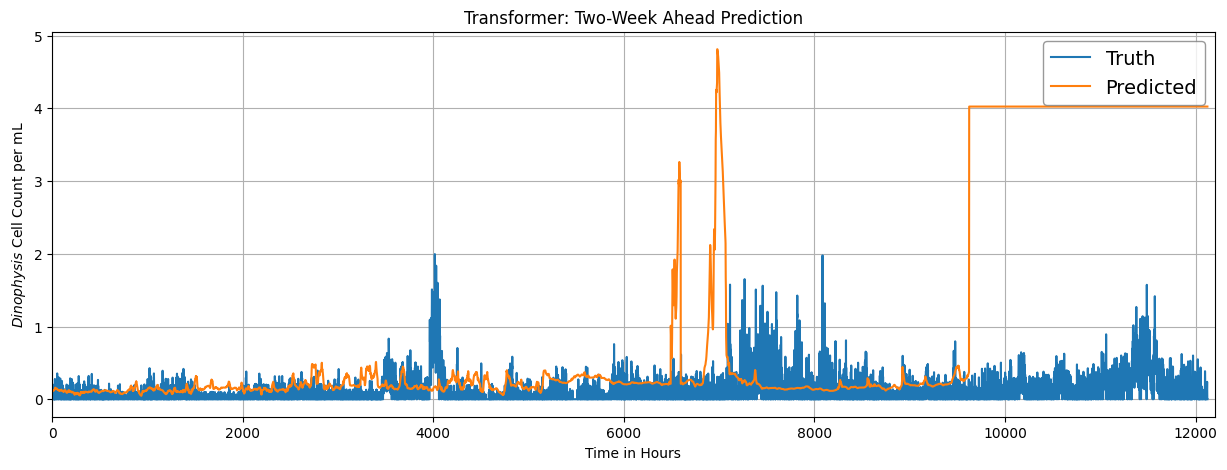

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(y_val, label="Truth")
plt.plot(y_pred, label="Predicted")

plt.title("Transformer: Two-Week Ahead Prediction")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.legend(fontsize=14, edgecolor='gray')
plt.xlim(0,12200)
plt.grid(True)

plt.show()

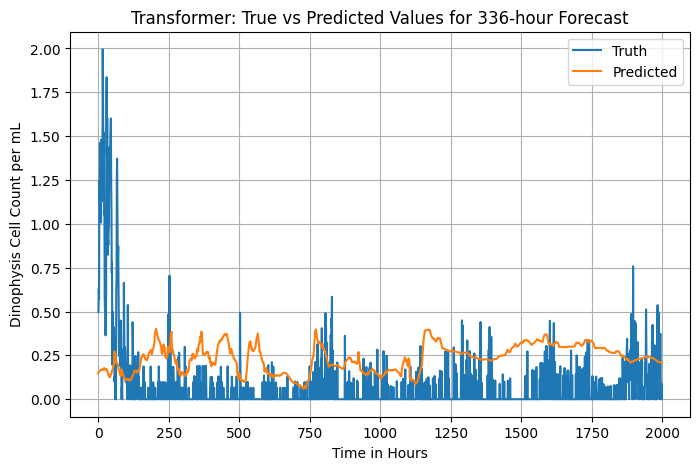

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(y_val[4000:6000], label="Truth")
plt.plot(y_pred[4000:6000], label="Predicted")

plt.title("Transformer: True vs Predicted Values for 336-hour Forecast")
plt.xlabel("Time in Hours")
plt.ylabel("Dinophysis Cell Count per mL")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
y_train_pred = model.predict(X_train)

y_train_pred = y_train_pred.flatten()

# Convert back from log scale
y_train_pred = np.expm1(y_train_pred)
y_train_true = np.expm1(y_train)

1516/1516 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step


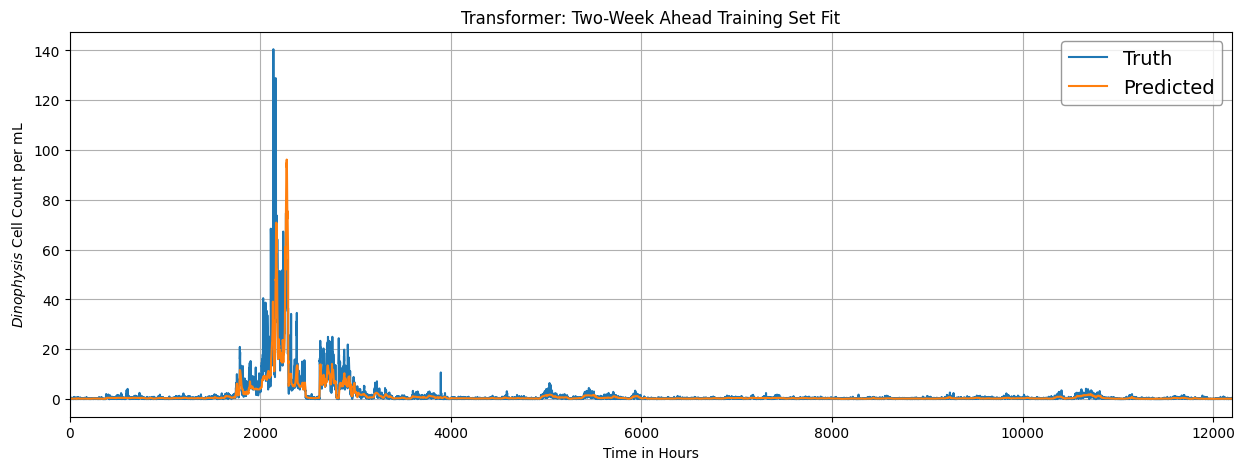

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(y_train_true, label="Truth")
plt.plot(y_train_pred, label="Predicted")

plt.title("Transformer: Two-Week Ahead Training Set Fit")
plt.xlabel("Time in Hours")
plt.ylabel(r"$\it{Dinophysis}$ Cell Count per mL")
plt.xlim(0,12200)
plt.legend(fontsize=14, edgecolor='gray')
plt.grid(True)

plt.show()